# CoEvoGraph-SWE: Co-Evolving Knowledge Graphs and Counterfactual World Models for Repository Repair

### Version-aware contract reasoning, competitive Gemma 4 agents, and execution-verified policy learning on NVIDIA DGX Spark

**Senthilkumar Vijayakumar, Sidharth E**

*Gemma 4 Developer Agent Paper Track. Executable companion notebook, version v2026-11-11. Every table and figure below is produced by the code cells that precede it, on one NVIDIA DGX Spark. Released under the Apache License 2.0.*

## Abstract

A coding agent can edit the right function and still break the contract that governed that version of the repository. The difficulty is often less about finding the code than about knowing which requirement was authoritative when the code was written. CoEvoGraph-SWE is an offline-first Gemma 4 system built around that question. It combines a provenance-scoped development knowledge graph, version-gated external documentation, a Contract-Conditioned Counterfactual Graph World Model (C³-GWM), protected execution, and an evidence ledger that feeds supervised fine-tuning and execution-rewarded reinforcement learning.

We evaluate it with Paired Temporal-Contract Interventions: a pair counts only when both the historical and the revised version of a requirement are repaired correctly. On 240 synthetic pairs in 20 families, time-valid evidence reaches a Paired Contract Success Rate (PCSR) of 0.735 on 15 held-out families, against 0.114 for a time-agnostic index (clustered difference +0.621, 95% CI 0.469 to 0.759). Swapping the validity flags drops PCSR to 0.111 on the first held-out set, so the agent acts on the validity markers it is shown. A contract-conditioned predictor almost doubles the AUPRC for predicting patch resolution before execution, from 0.217 to 0.410 over 6,480 executed interventions, and a shuffled-contract control falls to 0.131. Verified-witness memory lifts the version-1 resolve rate from 0.853 to 0.907. A LoRA adapter trained on verified edits takes strict pass@1 from 0.614 to 0.864 and cuts the mean rollout wall time from about 115 s to 20 s, and one round of execution-rewarded RL raises PCSR over the DPO checkpoint by 0.278 (95% CI 0.044 to 0.600). Serving, verification, world-model fitting and LoRA training all run on a single DGX Spark, with FP8 decoding at 860.9 tokens/s.

## Motivation

Consider two revisions of an authentication service. An earlier architecture decision, ADR-010 (2026-02-02), expires access tokens after 120 seconds. A later one, ADR-021 (2026-05-18), revises that to 40 seconds and makes the boundary exclusive. Both keep the invariant that signatures must always be verified. The bug report reads almost the same in both versions. A retrieval system that returns the newest or the most similar decision can produce valid Python that implements the wrong rule. The call graph tells you where the behavior lives, and the revision history tells you which behavior is correct. A patch needs both to be judged.

The distinction matters because a repair that passes a test written against ADR-021 is still wrong when it is applied to the earlier commit that ADR-010 governed. The historical cutoff is part of the task definition, so we evaluate the two contract versions as one paired unit: the agent has to change its answer when the governing decision changes, and keep the shared signature invariant while it does.

## Introduction

Repair benchmarks show one repository state and ask whether a patch passes. Real engineering decisions get revised: a token lifetime moves from 120 seconds to 40, a rounding rule is replaced. This notebook asks three questions about that setting and answers each with an experiment that runs on one local machine.

- **RQ1.** Does version-valid evidence improve contract-correct repair?
- **RQ2.** Can a world model predict, before execution, which patch honours the contract in force?
- **RQ3.** Can verified outcomes flow back into the agent, through witness memory and through a LoRA trained on verified edits, on the same device?

**Contributions.**

1. A version-scoped engineering-evidence pipeline and a paired evaluation, Paired Temporal-Contract Interventions: 240 synthetic pairs in 20 families and 19 natural pairs from 10 repositories, scored by PCSR with family-clustered bootstrap intervals.
2. Matched controls that isolate what the evidence contributes: a time-agnostic index and swapped validity flags.
3. C³-GWM, a contract-conditioned world model with a shuffled-contract control, evaluated by discrimination and by decision value.
4. An execution-verified loop on one DGX Spark: protected execution, a witness ledger, verified-witness memory, SFT and execution-rewarded RL.

**How the notebook is laid out.** Section 1 pins the testbed and Section 2 tests the verifier. Section 3 builds the benchmark and audits it for leakage. Sections 4, 5 and 6 answer RQ1, RQ2 and RQ3 in order, and Section 7 collects the findings and exports the tables.

## Architecture

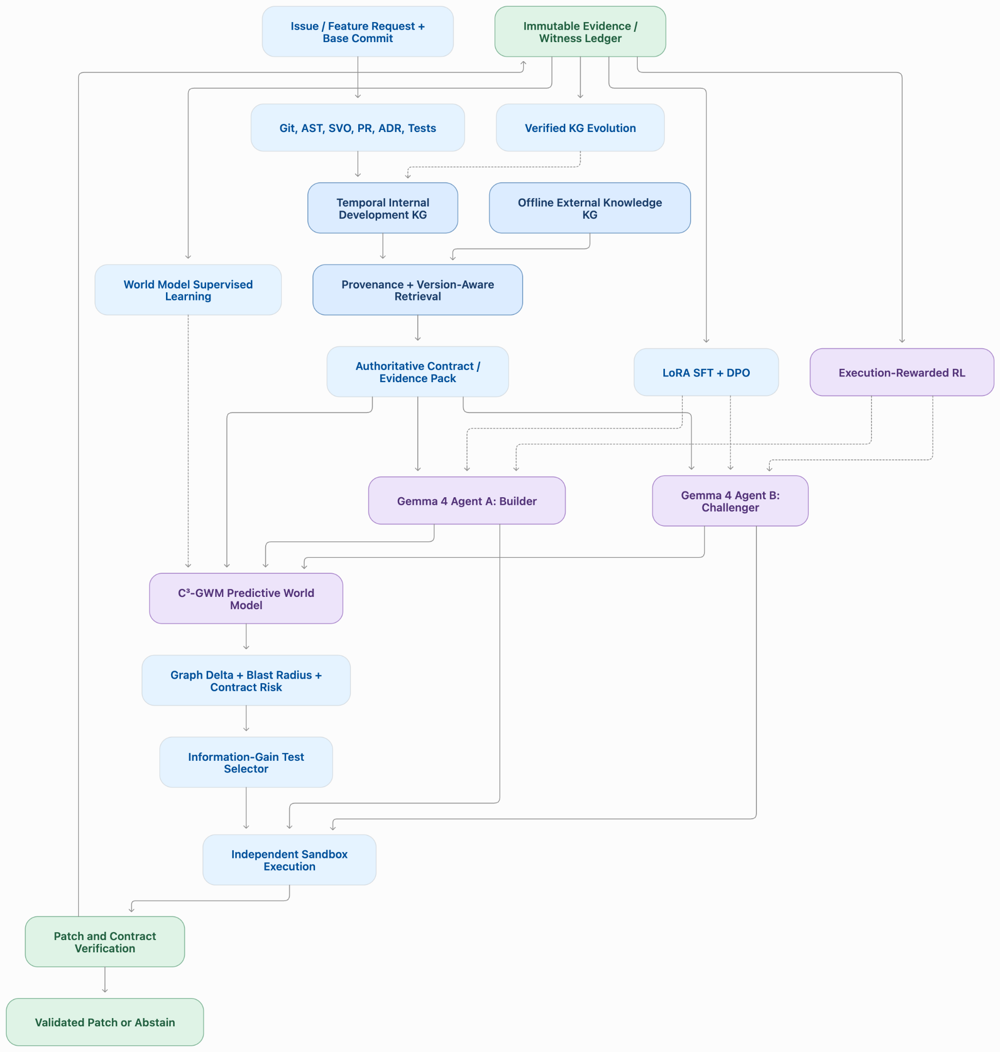

*Reference architecture. Blue boxes are deterministic components, purple boxes are learned or LLM components, green boxes are records and verdicts.*

An issue and a base commit enter the evidence layer. Git history, syntax trees, dated decision records and tests populate a time-versioned graph, and retrieval returns only records valid at the task date, with superseded records flagged. The Gemma 4 agent reads that evidence pack through SEARCH and VIEW tools and proposes a SEARCH/REPLACE edit. The edit runs in a sandbox on a pristine checkout, and trusted oracle files are overlaid after the patch. A world model predicts, before execution, whether the patch will satisfy the contract in force. Verified outcomes feed witness memory, adapter training and the world model, and held-out families never enter any of them.

| Layer | Role | Code | Section |
|:-|:-|:-|:-|
| Evidence | Time-versioned graph, time-valid retrieval, offline documentation gate | `coevo/kg.py`, `retrieval.py`, `extdocs.py` | 3, 4 |
| Agent | Gemma 4 12B, tool loop, SEARCH/REPLACE edit format | `coevo/agent.py` | 4 |
| Verifier | Fresh checkout, oracle overlay, resource limits | `coevo/tasks.py`, `sandbox.py` | 2 |
| World model | C³-GWM predicts patch success before execution | `coevo/worldmodel*.py`, `wm_eval.py` | 5 |
| Learning | Verified-witness memory, LoRA SFT, execution-rewarded RL | `coevo/b10.py`, `train.py`, `pipeline_*.py` | 6 |

The reference architecture also contains a Builder/Challenger escalation path. Its modules ship in the repository (`coevo/dual.py`, `probes.py`, `controller.py`), and this notebook concentrates on the layers in the table.

## How to read and run this notebook

Each code cell has a short lead-in before it and a reading of its output after it. Scores are reported with a strict parser (the edit header must contain `<<<<<<< SEARCH <path>`) and a lenient parser (a missing path is inferred when the search text occurs in exactly one non-test file). A contrast counts as a finding when its family-clustered 95% interval excludes 0 and the paired test agrees (Section 7).

**Terms.** PCSR is the share of pairs where the patch for the earlier contract and the patch for the revised contract both pass their own tests and the shared invariants. Evidence arms: B0 tools only, B1 adds retrieval and call graph, B2 adds time-valid decision records, B2s reads the same records from a time-agnostic index, B2x swaps the validity flags. World models: B5 reachability, B6 logistic regression, B7 gradient-boosted trees, B8 (C³-GWM) adds contract features, B8-shuffled receives another task's contract. Training: T0 untuned, T1 SFT, T2L DPO and T3aL one RL round, the last two trained on clean (lenient-parser) labels.

**To run.** Select the `coevo` kernel and run top to bottom. `PROFILE = "reuse"` (the default) recomputes every statistic from stored verified rollouts and runs the live GPU checks, about 10 to 15 minutes, most of it the vLLM server start. `"full"` also regenerates rollouts and retrains, which takes many hours. Cell 1.1 requires an NVIDIA GB10.

## Section 1. A pinned local testbed

Everything below runs on one NVIDIA DGX Spark (GB10): Gemma 4 12B-it served by vLLM with FP8 weights and an FP8 KV cache, the verifier, the world model and LoRA training. This section pins the stack and measures what the device can do, so every later number can be read against a known baseline.

### 1.1 Hardware guard, run switches and manifest

The first code cell confirms it is running on a GB10, fixes the profile and the seeds, and writes a manifest with SHA-256 hashes of adapters, task files, verifier code and prompt, plus package versions.

In [1]:
import os, sys, warnings, json, glob, time, collections, asyncio, subprocess, random, re
warnings.filterwarnings("ignore")
os.chdir(os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, os.getcwd())
from pathlib import Path
from dataclasses import asdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
from coevo.spark import require_spark, bench, write_manifest, ensure_server, stop_server, server_up, sha256_file, PY
from coevo.stats import load_results, arm_summary, pair_level, cluster_bootstrap_diff, mcnemar

HW = require_spark()                      # aborts unless this is the local GB10
PROFILE = "reuse"                         # "reuse": recompute from stored verified runs + live GPU benchmarks | "full": also re-run every stage
full = PROFILE == "full"
RUN = {"engine_bench": False,              # live bf16 / FP8 / FP8+KV decode benchmark (stops the server, ~15 min)
       "remine": full,                    # re-mine contract pairs from the cloned repositories
       "regen_interventions": full,       # re-execute the 6,480 world-model interventions
       "rerun_arms": full,                # fill missing B0-B4 / challenger / control / natural / training rollouts
       "rerun_b10": full,                 # recompute verified-memory arm (B10)
       "rerun_new_families": full,        # B1-B4 / controls / challenger rollouts on the 10 new stdlib-API families (power for B2 vs B1)
       "rerun_gat": full,                 # re-run the graph-attention world-model cross-validation (~30 min on the GB10)
       }
RUN_ID = time.strftime("%Y%m%d-%H%M%S"); RUN_DIR = Path("runs") / RUN_ID
SEEDS = {"sampling_temperature": 0.7, "rollout_samples_per_task": 3, "bootstrap_resamples": 4000, "wm_seed": 0, "mutation_seed": 11, "pool_seed": 3}
MANIFEST = write_manifest(RUN_DIR, {"profile": PROFILE, **RUN}, HW, SEEDS)

def sh(args, log=None):
    """Run `python -W ignore <args>` from the project root with the project interpreter; stdout/stderr to `log`."""
    cmd = [PY, "-W", "ignore", *(args.split() if isinstance(args, str) else args)]
    with open(log, "a") if log else open(os.devnull, "w") as fh:
        subprocess.run(cmd, cwd=".", stdout=fh, stderr=subprocess.STDOUT, check=True)

print("hardware:", {k: v for k, v in HW.items() if k != "host"}); print("profile:", PROFILE, RUN); print("run dir:", RUN_DIR)
print("manifest: adapters hashed:", len(MANIFEST["adapters_sha256"]), "| task files:", len(MANIFEST["task_files_sha256"]), "| versions:", MANIFEST["versions"])

hardware: {'gpu': 'NVIDIA GB10', 'driver': '580.178.04', 'compute_cap': '12.1', 'torch': '2.13.0+cu130', 'cuda_runtime': '13.0', 'platform': 'Linux-7.0.0-1019-nvidia-aarch64-with-glibc2.39', 'mem_total_gb': 113.8, 'cpus': 20}
profile: reuse {'engine_bench': False, 'remine': False, 'regen_interventions': False, 'rerun_arms': False, 'rerun_b10': False, 'rerun_new_families': False, 'rerun_gat': False}
run dir: runs/20261111-182810
manifest: adapters hashed: 14 | task files: 3 | versions: {'torch': '2.13.0', 'vllm': '0.32.0', 'transformers': '5.19.0', 'peft': '0.21.2', 'scikit-learn': '1.9.1', 'numpy': '2.3.5', 'pandas': '3.1.0'}


The guard passed on an NVIDIA GB10 (driver 580.178.04, torch 2.13.0+cu130, 20 CPUs). The profile is `reuse` and every `RUN` flag is off, so each table in the notebook is recomputed from stored verified rollouts. The manifest hashed 14 adapters and 3 task files and lists vllm 0.32.0, transformers 5.19.0 and peft 0.21.2. The 113.8 GB shown is the memory available at start; the machine has 121 GB of unified memory.

### 1.2 Where each layer lives in the code

A short map before the numbers. For each architecture layer the cell imports its modules, checks that the named object exists, and lists the notebook sections and pytest modules that exercise it.

In [2]:
import importlib
LAYERS = [("1 Ingestion", [("coevo.mining", None), ("coevo.synth", "generate"), ("coevo.tasks", "TaskStore")], "3.1 to 3.3", "test_split_audit"),
          ("2 Internal graph + claims", [("coevo.kg", "build_kg"), ("coevo.claims", "adjudicate")], "3.4 to 3.6", "test_temporal_cutoff, test_claims_adjudication"),
          ("3 External documentation graph", [("coevo.extdocs", "ExternalDocGraph")], "3.7", "test_external_gate"),
          ("4 Evidence retrieval", [("coevo.retrieval", "Retriever")], "4", "test_temporal_cutoff"),
          ("5 C3-GWM world model", [("coevo.worldmodel", "GBDTWorldModel"), ("coevo.worldmodel_gpu", "GPUMLPWorldModel"), ("coevo.worldmodel_gat", None)], "5", "-"),
          ("6 Agent", [("coevo.agent", "ARMS"), ("coevo.run_arm", "one")], "4", "-"),
          ("7 Verifier / ledger", [("coevo.sandbox", "run_pytest"), ("coevo.tasks", "verify_patch"), ("coevo.gold", "self_test")], "2, 3.3", "test_reward_integrity, test_sandbox_isolation"),
          ("8 Learning", [("coevo.b10", None), ("coevo.train", None), ("coevo.train_data", "reward"), ("coevo.pipeline_train_lenient", "main")], "6", "test_reward_integrity")]
rows = []
for name, mods, cells_, tests_ in LAYERS:
    ok = []
    for m_, attr in mods:
        try: mod_ = importlib.import_module(m_); ok.append(attr is None or hasattr(mod_, attr))
        except Exception as e: ok.append(False)
    rows.append({"layer": name, "modules": ", ".join(m_ for m_, _ in mods), "all present": all(ok), "notebook section": cells_, "pytest": tests_})
LAYER_MAP = pd.DataFrame(rows); print(LAYER_MAP.to_string(index=False))

                         layer                                                                modules  all present notebook section                                         pytest
                   1 Ingestion                                 coevo.mining, coevo.synth, coevo.tasks         True       3.1 to 3.3                               test_split_audit
     2 Internal graph + claims                                                 coevo.kg, coevo.claims         True       3.4 to 3.6 test_temporal_cutoff, test_claims_adjudication
3 External documentation graph                                                          coevo.extdocs         True              3.7                             test_external_gate
          4 Evidence retrieval                                                        coevo.retrieval         True                4                           test_temporal_cutoff
          5 C3-GWM world model           coevo.worldmodel, coevo.worldmodel_gpu, coevo.worldmodel_gat    

All eight rows show `all present = True`: every module imports in the current environment and exposes the object the notebook uses. The pytest column points at the test modules that guard each layer.

### 1.3 Hardware and software inventory

The GB10 shares one unified memory pool between CPU and GPU, so host memory bounds serving, training and verification together. The cell records device properties, package versions and memory.

In [3]:
import platform, torch, transformers, vllm, peft, sklearn
print(subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version,compute_cap,power.limit,clocks.max.sm", "--format=csv"], capture_output=True, text=True).stdout)
p = torch.cuda.get_device_properties(0)
print(f"{p.name} | SMs {p.multi_processor_count} | capability {p.major}.{p.minor} | CUDA runtime {torch.version.cuda}")
print("python", platform.python_version(), "| torch", torch.__version__, "| vllm", vllm.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__, "| sklearn", sklearn.__version__)
print(subprocess.run("free -g | head -2; echo cpus: $(nproc)", shell=True, capture_output=True, text=True).stdout)

name, driver_version, compute_cap, power.limit [W], clocks.max.sm [MHz]
NVIDIA GB10, 580.178.04, 12.1, [N/A], 3003 MHz

NVIDIA GB10 | SMs 48 | capability 12.1 | CUDA runtime 13.0
python 3.12.3 | torch 2.13.0+cu130 | vllm 0.32.0 | transformers 5.19.0 | peft 0.21.2 | sklearn 1.9.1
               total        used        free      shared  buff/cache   available
Mem:             121           8          83           0          31         113
cpus: 20



nvidia-smi reports an NVIDIA GB10 with driver 580.178.04, compute capability 12.1 and a 3003 MHz maximum SM clock. PyTorch sees 48 SMs and CUDA runtime 13.0. The versions (Python 3.12.3, torch 2.13.0+cu130, vllm 0.32.0, transformers 5.19.0, peft 0.21.2) match the manifest in 1.1. The machine has 121 GB of unified memory and 20 CPU cores, which is enough to hold the served model, a LoRA training run and the verifier workers at once.

### 1.4 Decode throughput: bf16, FP8 weights, FP8 weights plus FP8 KV cache

Every experiment below samples many rollouts, so decode speed sets how much can be explored. `coevo/bench_engine.py` times 64 concurrent requests of 256 new tokens on a fresh vLLM engine for each configuration. With `RUN["engine_bench"]` off, the cell reads the stored result.

engine_bench disabled: showing the STORED development benchmark only
                load_s  tok_per_s  tokens  seconds greedy_sample  speedup_vs_bf16
config                                                                           
bf16             202.1      452.3   16384     36.2       17 * 23            1.000
fp8_weights      245.8      763.4   16384     21.5       17 * 23            1.688
fp8_weights_kv   250.3      860.9   16384     19.0       17 * 23            1.903


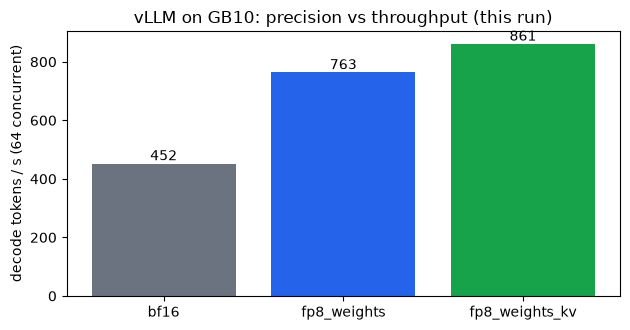

In [4]:
ENGINE_CFGS = {"bf16": {"dtype": "bfloat16"},
               "fp8_weights": {"dtype": "bfloat16", "quantization": "fp8"},
               "fp8_weights_kv": {"dtype": "bfloat16", "quantization": "fp8", "kv_cache_dtype": "fp8"}}
stored = pd.DataFrame([json.loads(l.split("RESULT ", 1)[1]) for l in open("logs/bench_engine.log") if l.startswith("RESULT")]).set_index("config")
fresh = []
if RUN["engine_bench"]:
    stop_server()
    for name, cfg in ENGINE_CFGS.items():
        with bench(f"engine:{name}", "benchmark", RUN_DIR) as b:
            r = subprocess.run([PY, "-W", "ignore", "coevo/bench_engine.py", json.dumps(cfg), name], capture_output=True, text=True, cwd=".")
        (RUN_DIR / f"engine_{name}.log").write_text(r.stdout + "\n" + r.stderr[-4000:])
        line = [l for l in r.stdout.splitlines() if l.startswith("RESULT")]
        assert line, f"engine benchmark {name} failed:\n{r.stderr[-1500:]}"
        rec = json.loads(line[-1].split("RESULT ", 1)[1]); rec.update(gpu_util_mean=b["gpu_util_mean"], power_w_mean=b["power_w_mean"], energy_wh=b["energy_wh"])
        fresh.append(rec)
    ENG = pd.DataFrame(fresh).set_index("config")
    ENG["speedup_vs_bf16"] = ENG.tok_per_s / ENG.tok_per_s.loc["bf16"]
    ENG["stored_tok_per_s"] = stored.tok_per_s
    ENG["tok_per_J"] = ENG.tokens / (ENG.energy_wh * 3600)
    (RUN_DIR / "engine_bench.json").write_text(ENG.reset_index().to_json(orient="records"))
else:
    ENG = stored.assign(speedup_vs_bf16=stored.tok_per_s / stored.tok_per_s.loc["bf16"])
    print("engine_bench disabled: showing the STORED development benchmark only")
print(ENG.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.4, 3.4)); bars = ax.bar(ENG.index, ENG.tok_per_s, color=["#6b7280", "#2563eb", "#16a34a"])
ax.bar_label(bars, fmt="%.0f"); ax.set_ylabel("decode tokens / s (64 concurrent)"); ax.set_title("vLLM on GB10: precision vs throughput (this run)"); plt.tight_layout(); plt.show()

Decode throughput is 452.3 tokens/s for bf16, 763.4 for FP8 weights (1.69 times) and 860.9 for FP8 weights plus FP8 KV cache (1.90 times). The greedy answer to `17*23` is the same in all three configurations. FP8 weights with an FP8 KV cache is the setting used for every later experiment.

### 1.5 A persistent serving endpoint and live throughput

The same engine now runs as a server. `ensure_server()` starts one vLLM server with FP8 weights and KV cache and a GPU memory fraction of 0.55, and the cell sends 64 concurrent requests through `coevo.llm.LLM`, dividing completion tokens by wall time.

In [5]:
with bench("vllm_server_start", "inference", RUN_DIR):
    ensure_server()
from coevo.llm import LLM, LEDGER
async def serve_bench(n=64, max_tokens=256):
    llm = LLM(concurrency=n)
    msgs = [[{"role": "user", "content": f"Write a detailed Python function number {i} that parses ISO dates and explain its edge cases."}] for i in range(n)]
    t0 = time.time(); await asyncio.gather(*[llm.chat(m, "nb:serve_bench", temperature=0.7, max_tokens=max_tokens) for m in msgs]); dt = time.time() - t0
    return LEDGER.summary()["nb:serve_bench"]["completion_tokens"] / dt, dt
with bench("serving_64x256", "inference", RUN_DIR) as b:
    SERVE_TPS, dt = await serve_bench()
print(f"serving throughput: {SERVE_TPS:.0f} completion tok/s over {dt:.1f}s | GPU util mean {b['gpu_util_mean']:.0f}% max {b['gpu_util_max']:.0f}% | power mean {b['power_w_mean']:.1f} W | energy {b['energy_wh']:.3f} Wh")

server gemma4-12b ready after 200s


serving throughput: 862 completion tok/s over 19.0s | GPU util mean 91% max 96% | power mean 44.8 W | energy 0.233 Wh


The server was ready after 200 s. 64 concurrent requests gave 862 completion tokens/s over 19.0 s, with mean GPU utilisation 91%, mean power 44.8 W and 0.233 Wh. That equals the stored engine figure of 860.9 tokens/s within 1%, so serving through the HTTP endpoint adds no visible overhead at this load.

## Section 2. The verifier: scoring that can be tested

A patch counts only if an independent verifier says so, so the verifier is tested before any model is scored. Gold patches must resolve and empty patches must not, tampering must earn nothing, a 142-test suite attacks the sandbox, and a replay audit re-verifies stored rollouts with the current code.

### 2.1 Gold resolves, empty fails, tampering earns nothing

`verify_patch` in `coevo/tasks.py` applies the edit to a pristine checkout, overlays trusted oracle files and runs the tests. The cell checks a click task over three repeats, then tries an edit to an oracle file, two `../` path escapes, a no-op and the gold patch on a synthetic task.

In [6]:
from coevo.tasks import TaskStore, verify_patch
from coevo.gold import gold_edits
from coevo.sandbox import sha256_text
from coevo import train_data as td
store = TaskStore()
nat_task = [x for x in store.tasks("natural") if "click" in x.task_id][0]
print("natural task:", nat_task.task_id, "| fail-to-pass:", nat_task.oracle_f2p[:2], "| pass-to-pass tests:", len(nat_task.oracle_p2p))
reps = [(verify_patch(store, nat_task, gold_edits(store, nat_task)), verify_patch(store, nat_task, "")) for _ in range(3)]
print("gold resolved x3:", [g.resolved for g, _ in reps], "| empty resolved x3:", [e.resolved for _, e in reps], "| gold seconds:", [round(g.seconds, 1) for g, _ in reps])
assert all(g.resolved for g, _ in reps) and not any(e.resolved for _, e in reps)
syn_task = store.tasks("synthetic")[0]; oracle = store.oracle_files(syn_task); rel = sorted(oracle)[0]
attack = f"<<<<<<< SEARCH {rel}\nassert\n=======\npass\n>>>>>>> REPLACE"
c_attack = verify_patch(store, syn_task, attack)
c_trav = verify_patch(store, syn_task, "<<<<<<< SEARCH ../outside.py\nx\n=======\ny\n>>>>>>> REPLACE"); c_trav2 = verify_patch(store, syn_task, "<<<<<<< SEARCH pkg/../../outside.py\nx\n=======\ny\n>>>>>>> REPLACE")
c_gold = verify_patch(store, syn_task, gold_edits(store, syn_task)); c_empty = verify_patch(store, syn_task, "")
rec = lambda c, text: {"cert": asdict(c), "text": text, "resolved": c.resolved}
INTEGRITY = {
    "edit of an oracle/test file is rejected": (not c_attack.applied) and "protected" in c_attack.apply_error,
    "protected-path edit gets reward -1": td.reward(rec(c_attack, attack)) == -1.0,
    "leading ../ cannot reach outside the workspace (normalised, then not found)": not c_trav.applied,
    "embedded ../ is rejected as an illegal path": (not c_trav2.applied) and "illegal path" in c_trav2.apply_error,
    "empty patch: unresolved, reward 0": (not c_empty.resolved) and td.reward(rec(c_empty, "")) == 0.0,
    "gold patch: resolved, reward > 1": c_gold.resolved and td.reward(rec(c_gold, "x")) > 1.0,
    "recorded oracle SHA-256 == trusted oracle": c_gold.oracle_sha256 == {k: sha256_text(v) for k, v in oracle.items()},
}
print(pd.Series(INTEGRITY, name="passed").to_string()); assert all(INTEGRITY.values())
print("certificate fields:", sorted(asdict(c_gold)))

natural task: nat-click-4aff026-f31d564-v0 | fail-to-pass: ['tests.test_utils::test_echo_writing_to_standard_error', 'tests.test_utils::test_prompts_abort'] | pass-to-pass tests: 69


gold resolved x3: [True, True, True] | empty resolved x3: [False, False, False] | gold seconds: [0.3, 0.3, 0.3]


edit of an oracle/test file is rejected                                        True
protected-path edit gets reward -1                                             True
leading ../ cannot reach outside the workspace (normalised, then not found)    True
embedded ../ is rejected as an illegal path                                    True
empty patch: unresolved, reward 0                                              True
gold patch: resolved, reward > 1                                               True
recorded oracle SHA-256 == trusted oracle                                      True
certificate fields: ['admissible', 'applied', 'apply_error', 'failed_tests', 'oracle_sha256', 'other_contract_pass', 'outcomes', 'own_pass', 'p2p_pass', 'patch_sha256', 'seconds', 'task_id', 'touched']


On the click task the gold patch resolved in 3 of 3 repeats and the empty patch in 0 of 3. All seven integrity checks print True: an edit to an oracle file is rejected, a protected-path edit gets reward -1, `../` paths are contained or rejected, an empty patch earns reward 0, the gold patch earns more than 1, and the oracle hashes match. Editing a test, escaping the workspace or submitting nothing earns no credit.

### 2.2 The pytest suite

The suite runs on real tasks and covers the temporal cutoff, reward integrity, the split audit, claim adjudication, sandbox isolation (socket guard and process-group kill) and the external documentation gate. The cell asserts zero failures.

In [7]:
import xml.etree.ElementTree as ET
with bench("pytest_suite", "verification", RUN_DIR):
    pr = subprocess.run([PY, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider", "--junitxml=runs/pytest_report.xml"], capture_output=True, text=True)
print(pr.stdout[-1500:])
_root = ET.parse("runs/pytest_report.xml").getroot(); _ts = _root if _root.tag == "testsuite" else _root[0]
PYTEST = {k: int(_ts.get(k, 0)) for k in ("tests", "failures", "errors", "skipped")}; PYTEST["passed"] = PYTEST["tests"] - PYTEST["failures"] - PYTEST["errors"] - PYTEST["skipped"]
print(PYTEST); assert PYTEST["failures"] + PYTEST["errors"] == 0, "pytest failures: a verifier / split / cutoff guarantee does not hold"

................................................................... [ 50%]
..............................................................x........  [100%]
142 passed, 1 xfailed in 64.98s (0:01:04)

{'tests': 143, 'failures': 0, 'errors': 0, 'skipped': 1, 'passed': 142}


The summary line reads `142 passed, 1 xfailed in 64.98s`, with 143 tests, 0 failures and 0 errors in the JUnit counts. The one expected failure documents a known property of the cutoff filter: undated chunks such as a CHANGELOG cannot be filtered by date.

### 2.3 Replay audit: stored rollouts re-verified with the current verifier

Stored results are only as good as the verifier that produced them. The cell draws 100 resolved and 100 applied-but-unresolved rollouts at random (seed 0) from the stored files and re-runs `verify_patch` on each, comparing the outcome and the individual test flags with the stored certificate. It also counts edits that touched protected paths across every stored rollout file.

In [8]:
from concurrent.futures import ThreadPoolExecutor
tasks_all = {t.task_id: t for t in store.tasks()}; pool = []
ROLLOUT_FILES = ["runs/main_synth_test.jsonl", "runs/eval_T1.jsonl", "runs/eval_T2.jsonl", "runs/eval_T3a.jsonl", "runs/eval_T3b.jsonl", "runs/train_rollouts_r0.jsonl"]
for f in ROLLOUT_FILES: pool += [json.loads(l) for l in open(f)]
rng = random.Random(0); win = rng.sample([r for r in pool if r["resolved"]], 100); lose = rng.sample([r for r in pool if not r["resolved"] and r["cert"]["applied"]], 100)
def replay(r):
    c = verify_patch(store, tasks_all[r["task_id"]], r["text"]); s = r["cert"]
    return (c.resolved == bool(r["resolved"]), (c.own_pass, c.p2p_pass, c.other_contract_pass) == (s["own_pass"], s["p2p_pass"], s["other_contract_pass"]))
with bench("replay_audit_200", "verification", RUN_DIR):
    with ThreadPoolExecutor(8) as ex_: a_ = list(ex_.map(replay, win)); b_ = list(ex_.map(replay, lose))
REPLAY = {"resolved_same_outcome": sum(x[0] for x in a_), "resolved_same_flags": sum(x[1] for x in a_), "unresolved_same_outcome": sum(x[0] for x in b_), "unresolved_same_flags": sum(x[1] for x in b_)}
print(REPLAY, "(each out of 100)")
protected = {f: sum(1 for l in open(f) if "protected" in json.loads(l)["cert"].get("apply_error", "")) for f in ROLLOUT_FILES}
print("rollouts per file:", {f: sum(1 for _ in open(f)) for f in ROLLOUT_FILES}); print("edits that touched protected paths:", protected)


{'resolved_same_outcome': 100, 'resolved_same_flags': 100, 'unresolved_same_outcome': 100, 'unresolved_same_flags': 100} (each out of 100)
rollouts per file: {'runs/main_synth_test.jsonl': 2160, 'runs/eval_T1.jsonl': 360, 'runs/eval_T2.jsonl': 360, 'runs/eval_T3a.jsonl': 360, 'runs/eval_T3b.jsonl': 360, 'runs/train_rollouts_r0.jsonl': 960}
edits that touched protected paths: {'runs/main_synth_test.jsonl': 0, 'runs/eval_T1.jsonl': 0, 'runs/eval_T2.jsonl': 0, 'runs/eval_T3a.jsonl': 0, 'runs/eval_T3b.jsonl': 0, 'runs/train_rollouts_r0.jsonl': 0}


All 200 replays reproduce the stored outcome and the stored test flags, 100 of 100 in each group. No rollout in any of the six files edited a protected path. The verifier gives the same answer today that it gave when the rollouts were generated.

## Section 3. The paired-contract benchmark and its leakage audit

One bug report, two decision records, two correct patches. This section looks at one pair in full, mines real revisions from git history, checks that every gold patch resolves (480 of 480 synthetic, 38 of 38 natural), and audits leakage: time-valid retrieval exposes 0 post-cutoff documents, while a time-agnostic index exposes the revising ADR in 240 of 240 version-0 tasks.

### 3.1 One pair, in full

A synthetic pair has one shared bug report, two dated ADRs where the later one supersedes the earlier, same-vocabulary decoy ADRs, a reference implementation for each contract, contract-specific tests and shared invariant tests (`coevo/synth.py`). The cell loads both splits from `TaskStore`, tabulates test counts and issue length per version, and prints one instance, `synth-expiry-03`.

NATURAL tasks: 38 | pairs: 19 | repositories: 10
   f2p   p2p  issue_chars
v                        
0  2.0  65.0         63.0
1  2.0  60.0         91.0

SYNTHETIC tasks: 480 | pairs: 240 | families: 20 | contract-specific tests per oracle (median): 5.0


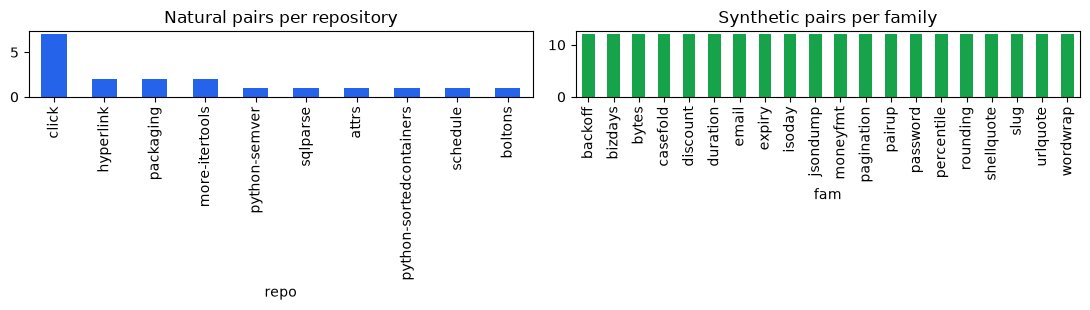

Example synthetic issue (identical for both versions):
  `compute_expiry` in `ledger_expiry/core.py` does not behave according to our current engineering contract for access token lifetime. Please fix it so it follows the contract documented in docs/adr.

[ADR-010] dated 2026-02-02
# ADR-010 Access-token lifetime
Date: 2026-02-02
Applies to: `ledger_expiry/core.py` (`compute_expiry`).

Access tokens expire 120 seconds after issue. A token is still valid at exactly 120 seconds of age and expired only strictly after that. Signature validation is mandatory at all times.


[ADR-021] dated 2026-05-18
# ADR-021 Access-token lifetime (revision)
Date: 2026-05-18
Applies to: `ledger_expiry/core.py` (`compute_expiry`).

This ADR revises ADR-010 (token lifetime). Access tokens now expire after 40 seconds. A token whose age equals 40 seconds is already expired (the boundary is exclusive). Signature validation remains mandatory.



In [9]:
nat = store.tasks("natural"); syn = store.tasks("synthetic")
dn = pd.DataFrame([{"pair": t.pair_id, "repo": t.family, "v": t.version, "f2p": len(t.oracle_f2p), "p2p": len(t.oracle_p2p), "issue_chars": len(t.issue)} for t in nat])
print("NATURAL tasks:", len(nat), "| pairs:", dn.pair.nunique(), "| repositories:", dn.repo.nunique()); print(dn.groupby("v")[["f2p", "p2p", "issue_chars"]].median().round(1).to_string())
ds = pd.DataFrame([{"fam": t.family, "v": t.version, "n_specific": t.meta["n_specific"]} for t in syn])
print("\nSYNTHETIC tasks:", len(syn), "| pairs:", len(syn) // 2, "| families:", ds.fam.nunique(), "| contract-specific tests per oracle (median):", ds.n_specific.median())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
dn.drop_duplicates("pair").repo.value_counts().plot.bar(ax=ax[0], color="#2563eb", title="Natural pairs per repository")
(ds.groupby("fam").size() // 2).plot.bar(ax=ax[1], color="#16a34a", title="Synthetic pairs per family"); plt.tight_layout(); plt.show()
ex = store.synth["synth-expiry-03"]; print("Example synthetic issue (identical for both versions):\n ", ex["issue"])
for k, (date, text) in ex["adr"].items(): print(f"\n[{k}] dated {date}\n{text}")

The synthetic split has 480 tasks in 240 pairs and 20 families of 12 pairs, with a median of 5 contract-specific tests per task. The natural split has 38 tasks in 19 pairs from 10 repositories; the median task has 2 fail-to-pass tests, 65 (version 0) or 60 (version 1) pass-to-pass tests, and an issue text of 63 or 91 characters. The printed instance is the example from the Motivation: one issue, ADR-010 at 120 seconds, ADR-021 at 40 seconds.

### 3.2 Real revisions mined from git history

Natural pairs come from `coevo/mining.py`: it finds a later commit that rewrites an assertion an earlier commit introduced, and validates the pair by running the tests. Nothing is read from commit messages. Because `RUN["remine"]` is off, the cell prints counts from the stored mining output.

In [10]:
if RUN["remine"]:
    os.makedirs("data/mined_nb", exist_ok=True)
    for f in glob.glob("data/mined_nb/*.jsonl"): os.remove(f)
    with bench("mine_pairs", "graph_building", RUN_DIR):
        subprocess.run('ls -d data/repos/* | xargs -P 6 -I{} sh -c ".venv-sbx/bin/python -W ignore -m coevo.mining {} data/mined_nb > /dev/null 2>&1"', shell=True, check=True)
    mined_dir = "data/mined_nb"
else:
    mined_dir = "data/mined"
rows = [json.loads(l) for f in sorted(glob.glob(f"{mined_dir}/*.jsonl")) for l in open(f)]
per_repo = collections.Counter(r["repo"] for r in rows)
print(f"{mined_dir}: {len(rows)} execution-validated supersession pairs in {len(per_repo)} repositories:", dict(per_repo.most_common()))
if RUN["remine"]:
    import io, contextlib
    from coevo.build_natural import main as build_natural
    buf = io.StringIO()
    with bench("build_natural_tasks", "graph_building", RUN_DIR), contextlib.redirect_stdout(buf):
        funnel = build_natural(mined_dir="data/mined_nb", out_path="data/tasks_nb/natural_pairs.jsonl", workers=6)
    old = {json.loads(l)["pair_id"] for l in open("data/tasks/natural_pairs.jsonl")}; new = {json.loads(l)["pair_id"] for l in open("data/tasks_nb/natural_pairs.jsonl")}
    print("funnel:", funnel, "| re-built pair set identical to the experiment dataset:", old == new, f"({len(old)} vs {len(new)})")

data/mined: 44 execution-validated supersession pairs in 12 repositories: {'click': 20, 'attrs': 4, 'more-itertools': 4, 'packaging': 4, 'hyperlink': 3, 'arrow': 2, 'sqlparse': 2, 'boltons': 1, 'pyjwt': 1, 'python-semver': 1, 'python-sortedcontainers': 1, 'schedule': 1}


The stored output holds 44 execution-validated supersession pairs in 12 repositories. Click supplies 20; attrs, more-itertools and packaging supply 4 each. The benchmark keeps the 19 pairs from 10 repositories that pass the filters in `coevo/build_natural.py`.

### 3.3 Every pair is attainable and no no-op is credited

`self_test(kind)` in `coevo/gold.py` runs every task through `verify_patch` twice, once with the real fix and once with an empty patch. Synthetic gold is the reference implementation, natural gold is the real fix.

In [11]:
from coevo.gold import self_test
with bench("verifier_self_test_all_tasks", "verification", RUN_DIR) as b:
    res_nat = self_test("natural"); res_syn = self_test("synthetic")
print(f"natural   : {res_nat['gold_resolved']}/{res_nat['n']} gold resolved, {res_nat['empty_resolved']} empty-patch false positives, bad={res_nat['bad']}")
print(f"synthetic : {res_syn['gold_resolved']}/{res_syn['n']} gold resolved, {res_syn['empty_resolved']} empty-patch false positives, bad={res_syn['bad']}")
print(f"{2 * (res_nat['n'] + res_syn['n'])} sandboxed verifications in {b['wall_s']:.0f}s ({b['wall_s'] / (2 * (res_nat['n'] + res_syn['n'])):.2f} s each, parallel x10)")

natural   : 38/38 gold resolved, 0 empty-patch false positives, bad=[]
synthetic : 480/480 gold resolved, 0 empty-patch false positives, bad=[]
1036 sandboxed verifications in 42s (0.04 s each, parallel x10)


Natural: 38 of 38 gold patches resolved and 0 empty patches. Synthetic: 480 of 480 resolved and 0 empty. The 1,036 verifications (518 tasks, 2 each) took 42 s. Every task can be solved, and doing nothing never scores.

### 3.4 Time-valid retrieval exposes nothing from the future

Section 4 compares a time-valid index with a time-agnostic one, so the first thing to establish is that the time-valid index never shows a document dated after the task. For all 480 synthetic tasks, `build_kg` builds both workspaces, each wrapped in `Retriever`, and the cell counts post-cutoff documents in each.

In [12]:
from coevo.kg import build_kg
from coevo.retrieval import Retriever
viol_valid = viol_agn = leaks_v0 = checked = 0
for t in syn:
    with store.workspace(t) as ws: r = Retriever(build_kg(ws), t.cutoff, time_valid=True)
    with store.workspace(t, time_agnostic=True) as ws: a = Retriever(build_kg(ws), t.cutoff, time_valid=False)
    viol_valid += sum(1 for d in r.docs if d.date and d.date > t.cutoff)
    fut = [d for d in a.docs if d.date and d.date > t.cutoff]; viol_agn += len(fut); leaks_v0 += (t.version == 0 and len(fut) > 0); checked += 1
print(f"tasks checked: {checked}")
print(f"post-cutoff documents visible to TIME-VALID retrieval : {viol_valid}   (must be 0)")
print(f"post-cutoff documents visible to TIME-AGNOSTIC index  : {viol_agn}")
print(f"version-0 tasks whose static index contains the future revising ADR: {leaks_v0}/{sum(t.version == 0 for t in syn)}")
TEMPORAL_OK = viol_valid == 0; assert TEMPORAL_OK

tasks checked: 480
post-cutoff documents visible to TIME-VALID retrieval : 0   (must be 0)
post-cutoff documents visible to TIME-AGNOSTIC index  : 240
version-0 tasks whose static index contains the future revising ADR: 240/240


Over 480 tasks, post-cutoff documents visible to time-valid retrieval: 0. Visible to the time-agnostic index: 240, which is the future revising ADR in all 240 version-0 tasks. The time-agnostic index does leak the future, so the gap between the two arms in Section 4 comes from how validity is handled.

### 3.5 The time-versioned development knowledge graph

`coevo/kg.py` builds the graph without a model: `ast` gives code nodes and edges, and regular expressions read ADR dates and "revises" phrases. `resolve_supersession(cutoff)` marks an ADR superseded only if its successor is dated on or before the cutoff.

synthetic snapshot: nodes 29 edges 35 {'MENTIONS': 2, 'SUPERSEDES': 1, 'IMPORTS': 5, 'DEFINES': 11, 'CALLS': 10, 'TESTS': 6} | provenance: {'document-claimed': 3, 'observed': 32}
ADR status at cutoff: [('ADR-001', '2026-01-05', 'in force'), ('ADR-002', '2026-01-12', 'in force'), ('ADR-010', '2026-02-02', 'SUPERSEDED by ADR-021'), ('ADR-015', '2026-01-20', 'in force'), ('ADR-018', '2026-01-25', 'in force'), ('ADR-021', '2026-05-18', 'in force')]


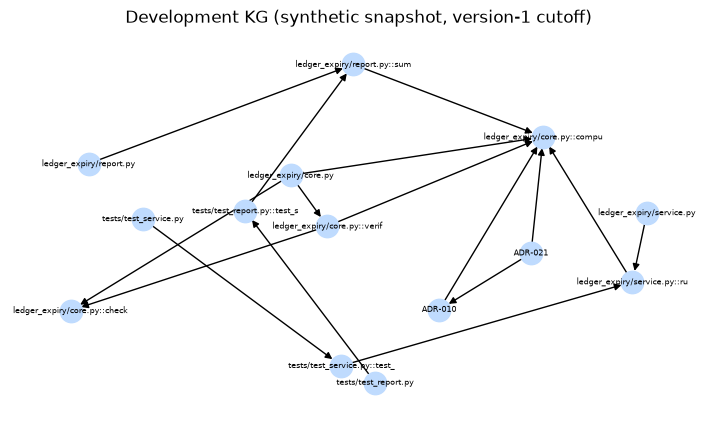

natural snapshot nat-click-4aff026-f31d564-v1: nodes 1616 edges 6598 python files 63 doc chunks 240


In [13]:
import networkx as nx
t1 = [t for t in syn if t.task_id == "synth-expiry-03-v1"][0]
with bench("kg_build_synthetic_snapshot", "graph_building", RUN_DIR):
    with store.workspace(t1) as ws: kg = build_kg(ws); kg.resolve_supersession(t1.cutoff)
rels = collections.Counter(d["rel"] for _, _, d in kg.graph.edges(data=True)); prov = collections.Counter(d["provenance"] for _, _, d in kg.graph.edges(data=True))
print("synthetic snapshot: nodes", kg.graph.number_of_nodes(), "edges", kg.graph.number_of_edges(), dict(rels), "| provenance:", dict(prov))
print("ADR status at cutoff:", [(d.doc_id, d.date, "SUPERSEDED by " + d.superseded_by if d.superseded_by else "in force") for d in kg.docs if d.doc_id.startswith("ADR")])
sub = nx.DiGraph([(u.split(":", 1)[-1][:28], v.split(":", 1)[-1][:28]) for u, v, d in kg.graph.edges(data=True) if d["rel"] in ("CALLS", "TESTS", "MENTIONS", "SUPERSEDES", "DEFINES") and not v.startswith("import:")])
plt.figure(figsize=(9, 5)); nx.draw_networkx(sub, nx.spring_layout(sub, seed=2, k=0.9), node_size=260, font_size=6, node_color="#bfdbfe"); plt.axis("off"); plt.title("Development KG (synthetic snapshot, version-1 cutoff)"); plt.show()
nt = nat[1]
with store.workspace(nt) as ws: kn = build_kg(ws)
print(f"natural snapshot {nt.task_id}: nodes {kn.graph.number_of_nodes()} edges {kn.graph.number_of_edges()} python files {len(kn.sources)} doc chunks {len(kn.docs)}")

The version-1 snapshot of `synth-expiry-03` has 29 nodes and 35 edges: DEFINES 11, CALLS 10, TESTS 6, IMPORTS 5, MENTIONS 2 and SUPERSEDES 1. At the cutoff, ADR-010 reads "SUPERSEDED by ADR-021" and the other five ADRs are in force. The click snapshot has 1,616 nodes and 6,598 edges.

### 3.6 Gemma 4 proposes claims, a deterministic adjudicator accepts them

The evidence layer can also hold claims extracted by the model. `coevo.claims.propose` asks Gemma 4 for subject-predicate-object triples with a verbatim quote from each of 80 ADRs, and `adjudicate` accepts a claim only if the quote is verbatim, the predicate is allowed and the entities are grounded in the graph.

In [14]:
from coevo.claims import propose, adjudicate
ensure_server(); llm = LLM(concurrency=24)
docs = []
for pid in list(store.synth)[:40]:
    rec_ = store.synth[pid]; t = [x for x in syn if x.task_id == pid + "-v1"][0]
    with store.workspace(t) as ws: kg_ = build_kg(ws)
    for name, (date, text) in rec_["adr"].items(): docs.append((pid, name, text, kg_))
with bench("svo_claims_llm", "inference", RUN_DIR) as b:
    claims = await asyncio.gather(*[propose(llm, name, text) for _, name, text, _ in docs])
tot = ver = found_sup = n21 = 0; reasons = collections.Counter()
for (pid, name, text, kg_), cl in zip(docs, claims):
    got = False
    for c in cl:
        status, why = adjudicate(c, name, text, kg_); tot += 1; ver += status == "verified"; reasons[why or "ok"] += 1
        if name == "ADR-021" and status == "verified" and str(c.get("predicate", "")).upper() == "SUPERSEDES" and "ADR-010" in str(c.get("object", "")).upper() + str(c.get("subject", "")).upper(): got = True
    if name == "ADR-021": n21 += 1; found_sup += got
CLAIMS = {"documents": len(docs), "proposed": tot, "verified": ver, "supersession_recovered": found_sup, "supersession_docs": n21}
print(f"documents: {len(docs)} | proposed: {tot} | verified: {ver} ({ver / max(tot, 1):.0%}) | quarantined: {tot - ver} | {b['wall_s']:.0f}s")
print("adjudication outcomes:", dict(reasons)); print(f"true supersession fact recovered and verified in {found_sup}/{n21} revising ADRs")

documents: 80 | proposed: 236 | verified: 223 (94%) | quarantined: 13 | 42s
adjudication outcomes: {'ok': 223, 'entity_not_grounded': 13}
true supersession fact recovered and verified in 40/40 revising ADRs


80 documents gave 236 proposed claims. 223 were verified (94%) and 13 were quarantined, all as `entity_not_grounded`, so the guard keeps ungrounded claims out of the graph. The true supersession fact was found and verified in 40 of 40 revising ADRs.

### 3.7 An offline documentation graph with an explicit gap marker

`ExternalDocGraph` in `coevo/extdocs.py` reads a frozen offline snapshot. The gated pack holds only symbols the task imports and marks anything missing as `[EVIDENCE GAP]`, so the agent is told what is not known. The cell builds both the gated and the always-on pack for 518 tasks.

In [15]:
from coevo import extdocs
from coevo.retrieval import imported_modules
EKG = extdocs.ExternalDocGraph()
snap = pd.DataFrame([{"entry": k, "package": v["package"], "version": v["version"], "license": v["license"]} for k, v in EKG.entries.items()])
print("frozen entries:", len(snap), "| packages:", snap.groupby("package").size().to_dict())
SNAP_HASHES = {v["sha256"][:10] for v in EKG.entries.values()}; ok_subset = n_t = gaps = bad_prov = invented = 0; extra_always = []
for t in nat + syn:
    with store.workspace(t) as ws:
        kg_ = build_kg(ws); ret = Retriever(kg_, t.cutoff)
        touched = [store.synth[t.pair_id]["target_file"]] if t.kind == "synthetic" else t.src_files[:3]
        txt_g, ev_g = ret.external_evidence(touched, True); txt_a, ev_a = ret.external_evidence(touched, False); mods = {m.split(".")[0] for m in imported_modules(kg_, touched)}
    n_t += 1; ok_subset += all(e.module.split(".")[0] in mods for e in ev_g); extra_always.append(sum(e.module.split(".")[0] not in mods for e in ev_a))
    gaps += sum(e.status == "gap" for e in ev_g); bad_prov += sum(e.status == "ok" and EKG.entries[f"{e.module}::{e.symbol or ''}"]["sha256"] != e.sha256 for e in ev_g)
    invented += sum(1 for h in re.findall(r"\[external: [^\]]*sha256:(\w{10})\]", txt_g + txt_a) if h not in SNAP_HASHES)
gap_demo = EKG.lookup("definitely_not_a_module").render(); ver_demo = EKG.lookup("click", None, "<7").render()
GATE = {"tasks": n_t, "gated_pack_only_imported_modules": int(ok_subset), "mean_unrelated_modules_in_always_on_pack": float(np.mean(extra_always)), "explicit_gap_markers_in_gated_packs": int(gaps),
        "unknown_module_doc": None if "[EVIDENCE GAP" in gap_demo else gap_demo, "version_mismatch_flagged": "[VERSION MISMATCH" in ver_demo, "provenance_hash_mismatches": int(bad_prov), "invented_citations": int(invented)}
print(GATE); print(gap_demo); print(ver_demo)
assert GATE["gated_pack_only_imported_modules"] == GATE["tasks"] and GATE["unknown_module_doc"] is None and GATE["version_mismatch_flagged"] and GATE["provenance_hash_mismatches"] == 0 and GATE["invented_citations"] == 0

frozen entries: 143 | packages: {'attrs': 4, 'click': 1, 'matplotlib': 1, 'numpy': 1, 'packaging': 1, 'pillow': 1, 'pyparsing': 1, 'pytest': 1, 'python': 129, 'scipy': 1, 'setuptools': 2}


{'tasks': 518, 'gated_pack_only_imported_modules': 518, 'mean_unrelated_modules_in_always_on_pack': 4.61003861003861, 'explicit_gap_markers_in_gated_packs': 57, 'unknown_module_doc': None, 'version_mismatch_flagged': True, 'provenance_hash_mismatches': 0, 'invented_citations': 0}
[EVIDENCE GAP: no authorised offline documentation for `definitely_not_a_module` (third-party and not in frozen snapshot); do not assume its behaviour]
[VERSION MISMATCH: `click` documented for click 8.5.0 but repository pins `<7`; documentation withheld]


The snapshot has 143 entries, 129 of them from the standard library. Over 518 tasks the gated pack held only imported modules in 518 of 518 cases, while the always-on pack added a mean of 4.61 unrelated modules. The gated packs carry 57 explicit gap markers, with 0 hash mismatches and 0 invented citations.

## Section 4. Experiment 1 (RQ1): does the agent follow the contract in force?

Same model, same prompt, same tools, same verifier. Only the evidence changes. If the agent reads validity markers, correct markers should help and wrong ones should hurt. They do. On the first held-out set, B2 (time-valid records) reaches PCSR 0.789, the same records from a time-agnostic index give 0.200, and the same records with inverted flags give 0.111. Across 15 held-out families the gap between B2 and B2s is +0.621 (95% CI 0.469 to 0.759).

### 4.1 The arms

`coevo.agent.ARMS` holds one record per arm. B2 adds `contract=valid` to B1. The two controls change one thing each: B2s reads a time-agnostic index and B2x inverts B2's validity flags. The cell prints the arm table and the number of stored rollouts per file.

In [16]:
from coevo.agent import ARMS
print(pd.DataFrame([vars(a) for a in ARMS.values()]).set_index("name").to_string())
HELD = "discount,password,email,bizdays,slug"; TRAIN = "expiry,rounding,pagination,backoff,bytes"
ARM_RUNS = [("main_synth_test", f"--kind synthetic --arms B0,B1,B2,B2s,B3,B4 --k 3 --families {HELD}"),
            ("challenger_synth_test", f"--kind synthetic --arms B4c --k 3 --families {HELD}"),
            ("control_swap_test", f"--kind synthetic --arms B2x --k 3 --families {HELD}"),
            ("main_natural", "--kind natural --arms B0,B1,B2,B2s,B3,B4 --k 2"),
            ("train_rollouts_r0", f"--kind synthetic --arms B4 --k 8 --temperature 1.0 --families {TRAIN}")]
if RUN["rerun_arms"]:
    ensure_server()
    for name, args in ARM_RUNS:
        with bench(f"arms:{name}", "inference", RUN_DIR):
            sh(f"-m coevo.run_arm {args} --out runs/{name}.jsonl", f"logs/{name}.log")
    from coevo import rescore
    with bench("lenient_rescore", "verification", RUN_DIR):
        rescore.main([n for n, _ in ARM_RUNS])
print({n: sum(1 for _ in open(f"runs/{n}.jsonl")) for n, _ in ARM_RUNS if n in ("main_synth_test", "control_swap_test", "train_rollouts_r0")})

      structural   contract external tool_index  swap_validity
name                                                          
B0         False        NaN      NaN      valid          False
B1          True        NaN      NaN      valid          False
B2          True      valid      NaN      valid          False
B2s         True     static      NaN   agnostic          False
B3          True      valid   always      valid          False
B4          True      valid    gated      valid          False
B2x         True      valid      NaN      valid           True
B4c         True  valid_alt    gated      valid          False
{'main_synth_test': 2160, 'control_swap_test': 360, 'train_rollouts_r0': 960}


B2 differs from B1 by `contract=valid`. B2s uses `contract=static` with `tool_index=agnostic`, and B2x sets `swap_validity=True`. The stored held-out rollouts are 2,160 in `main_synth_test` (6 arms, 120 tasks, 3 samples), 360 in `control_swap_test` and 960 in `train_rollouts_r0`.

### 4.2 The evidence ladder, strict and lenient parsing side by side

`arm_summary` computes pass@1, PCSR (both versions must resolve at the same sample) with a family-clustered 95% interval, the wrong-contract rate and the share of edits that applied. The strict parser needs a path in the edit header and the lenient re-scorer infers it.

In [17]:
ORDER = ["B0", "B1", "B2", "B2s", "B2x"]
sf = ("runs/main_synth_test.jsonl", "runs/control_swap_test.jsonl"); lf = tuple(p.replace("runs/", "runs/lenient/") for p in sf)
df_strict, df = load_results(*sf), load_results(*lf)
print("lenient rollouts:", df.groupby("arm").size().to_dict(), "| tasks:", df.task_id.nunique(), "| pairs:", df.pair_id.nunique(), "| families:", sorted(df.family.unique()))
tab = arm_summary(df, ORDER).set_index("arm"); tab_s = arm_summary(df_strict, ORDER).set_index("arm")
print("\nLENIENT parser:"); print(tab.round(3).to_string())
print("\nSTRICT parser (PCSR / pass@1 / applied):"); print(tab_s[["pass@1", "PCSR", "PCSR_lo", "PCSR_hi", "applied"]].round(3).to_string())

lenient rollouts: {'B0': 360, 'B1': 360, 'B2': 360, 'B2s': 360, 'B2x': 360, 'B3': 360, 'B4': 360} | tasks: 120 | pairs: 60 | families: ['bizdays', 'discount', 'email', 'password', 'slug']



LENIENT parser:
     n_rollouts  pass@1   PCSR  PCSR_lo  PCSR_hi  wrong_contract  applied  own_pass  inv_pass  turns   wall_s
arm                                                                                                          
B0          360   0.792  0.606    0.367    0.783           0.008    0.897     0.792     0.875  5.200  225.683
B1          360   0.867  0.750    0.594    0.889           0.006    0.972     0.867     0.947  4.642  113.293
B2          360   0.869  0.789    0.422    0.983           0.000    0.989     0.869     0.989  3.739  114.687
B2s         360   0.519  0.200    0.028    0.361           0.294    0.981     0.519     0.978  3.575  124.853
B2x         360   0.519  0.111    0.017    0.267           0.403    0.983     0.519     0.981  3.756  119.425

STRICT parser (PCSR / pass@1 / applied):
     pass@1   PCSR  PCSR_lo  PCSR_hi  applied
arm                                          
B0    0.411  0.183    0.089    0.300    0.492
B1    0.508  0.294    0.194    0.

Five arms, 360 rollouts each, 60 held-out pairs from five families. Lenient PCSR climbs from 0.606 for tools only (B0) to 0.750 with structural retrieval (B1) and 0.789 with time-valid decision records (B2). Feed the same records through a time-agnostic index and PCSR drops to 0.200 (B2s); invert the flags and it drops to 0.111 (B2x). The wrong-contract rate shows why: 0.000 for B2, 0.294 for B2s and 0.403 for B2x, while the share of edits that applied stays near 0.98 for all three. Strict PCSR keeps the same shape, with B2 at 0.428.

The controls write well-formed patches for the wrong version. A model that trusts the markers it is given follows whichever record is marked as in force, which is why correct markers are worth having.

### 4.3 Fresh rollouts on the live server

The tables above come from stored rollouts. To see the pipeline work end to end, `coevo.run_arm.one` runs `synth-bizdays-01-v1` under B0 and B2 at temperature 0.7 with a new sample index (99), and `verify_patch` scores each reply with the strict parser. These draws are new and enter no table.

In [18]:
from coevo.run_arm import one
ensure_server(); llm = LLM(concurrency=8)
task = [t for t in store.tasks("synthetic") if t.task_id == "synth-bizdays-01-v1"][0]
with bench("live_rollouts_B0_B2", "inference", RUN_DIR) as b:
    recs = await asyncio.gather(*[one(llm, store, task, arm, 99, None, 0.7) for arm in ("B0", "B2")])
for r in recs:
    c = r["cert"]
    print(f"--- arm {r['arm']} | turns {r['rollout']['turns']} tools {r['rollout']['tool_calls']} | applied={c['applied']} own={c['own_pass']} inv={c['p2p_pass']} wrong_contract={r['wrong_contract']} resolved={r['resolved']} ({r['wall_s']}s)")
    print(r["text"][:500]); print()

--- arm B0 | turns 6 tools ['SEARCH: docs/adr/ADR-021-bizdays.md', 'VIEW: docs/adr/ADR-021-bizdays.md', 'VIEW: gateway_bizdays/core.py'] | applied=False own=False inv=False wrong_contract=False resolved=False (14.59s)
<<<<<<< SEARCH
    HOL = ['2026-03-03']
    HOL = ['2026-03-03', '2026-03-12']
>>>>>>> REPLACE

--- arm B2 | turns 1 tools [] | applied=True own=True inv=True wrong_contract=False resolved=True (20.53s)
thought
SEARCH: docs/adr/ADR-021-bizdays.md
thought
thought
VIEW: gateway_bizdays/core.py
thought
thought
<<<<<<< SEARCH gateway_bizdays/core.py
def normalize_bizdays(start_iso, n):
    """Add ``n`` business days to an ISO date and return an ISO date."""
    start = date.fromisoformat(start_iso)
    HOL = ['2026-03-03']
    d = start
    left = n
    while left > 0:
        d += timedelta(days=1)
        if d.weekday() < 5 and d.isoformat() not in HOL:
            left -= 1
    return d.isoforma



One fresh sample per arm, so this illustrates the pipeline and is not a statistic. B2 resolved the task in 1 turn straight from the evidence pack: the edit applied and the own-contract and invariant tests pass. B0 searched for ADR-021 and read the source over 6 turns, and its final edit header carried no file path, so it did not apply and the sample did not resolve.

### 4.4 Paired tests on held-out set 1

`pair_level` gives per-pair PCSR over the three samples. `cluster_bootstrap_diff` resamples whole families (4,000 draws) for a 95% interval on A minus B, and `mcnemar` adds an exact test on discordant pairs as supporting evidence. Four contrasts carry the argument: B2 against the two controls, and the lift from retrieval and from decision records over tools only.

In [19]:
comps = [("B2", "B2s", "time-valid vs time-agnostic index"), ("B2", "B2x", "time-valid vs swapped validity flags"), ("B2", "B0", "time-valid records vs tools only"), ("B1", "B0", "structural retrieval vs tools only")]
rows = []
for a, b, note in comps:
    pa, pb = pair_level(df, a), pair_level(df, b); d = cluster_bootstrap_diff(pa, pb); m = mcnemar(pa, pb)
    rows.append({"A": a, "B": b, "what": note, "dPCSR": d["diff"], "CI_lo": d["ci_lo"], "CI_hi": d["ci_hi"], "pairs": d["n_pairs"], "A_only": m["a_only"], "B_only": m["b_only"], "McNemar_p": m["p_value"]})
ARM_TESTS = pd.DataFrame(rows); print(ARM_TESTS.round(3).to_string(index=False))

 A   B                                 what  dPCSR  CI_lo  CI_hi  pairs  A_only  B_only  McNemar_p
B2 B2s    time-valid vs time-agnostic index  0.589  0.306  0.844     60      36       0      0.000
B2 B2x time-valid vs swapped validity flags  0.678  0.333  0.917     60      46       0      0.000
B2  B0     time-valid records vs tools only  0.183  0.011  0.333     60      13       0      0.000
B1  B0   structural retrieval vs tools only  0.144  0.078  0.217     60      14       3      0.013


Four contrasts on 60 pairs from 5 families. B2 minus B2s is +0.589 (95% CI 0.306 to 0.844), with 36 pairs won by B2 and none by B2s. B2 minus B2x is +0.678 (0.333 to 0.917), 46 pairs to none. B2 minus B0 is +0.183 (0.011 to 0.333), 13 pairs to none, and B1 minus B0 is +0.144 (0.078 to 0.217). Each interval rests on 5 family clusters, so Section 4.5 repeats the test on 15.

### 4.5 Ten more held-out families

Ten further families built on real standard-library behavior (`json.dumps`, `urllib.parse.quote`, `textwrap`, `shlex`, `Decimal` rounding and others) add 120 pairs. They were never used for training or fitting. The cell repeats the paired tests on the pooled 15 families and adds the minimum detectable effect (MDE, 2.8 standard errors).

new-family rollouts: {'B1': 480, 'B2': 480, 'B2s': 480, 'B2x': 480, 'B3': 480, 'B4': 480, 'B4c': 480} | families: 10 | pairs: 120 | pooled held-out families: 15



new families (lenient)
     n_rollouts  pass@1   PCSR  PCSR_lo  PCSR_hi  wrong_contract  applied
arm                                                                      
B1          480   0.754  0.588    0.404    0.767           0.046    0.990
B2          480   0.829  0.708    0.517    0.879           0.000    0.988
B2s         480   0.417  0.071    0.017    0.138           0.317    0.992
B2x         480   0.496  0.083    0.025    0.154           0.408    0.994

all 15 held-out families (lenient)
     n_rollouts  pass@1   PCSR  PCSR_lo  PCSR_hi  wrong_contract  applied
arm                                                                      
B1          840   0.802  0.642    0.501    0.774           0.029    0.982
B2          840   0.846  0.735    0.557    0.883           0.000    0.988
B2s         840   0.461  0.114    0.044    0.192           0.307    0.987
B2x         840   0.506  0.093    0.035    0.157           0.406    0.989

new families (strict)
     n_rollouts  pass@1   PCS


          scope  A   B                                 what  dPCSR  CI_lo  CI_hi  pairs  families  McNemar_p  MDE_80pct_power
 old 5 families B2 B2s    time-valid vs time-agnostic index  0.589  0.306  0.844     60         5      0.000            0.385
 old 5 families B2 B2x time-valid vs swapped validity flags  0.678  0.333  0.917     60         5      0.000            0.417
 old 5 families B2  B0     time-valid records vs tools only  0.183  0.011  0.333     60         5      0.000            0.230
 old 5 families B1  B0   structural retrieval vs tools only  0.144  0.078  0.217     60         5      0.013            0.099
new 10 families B2 B2s    time-valid vs time-agnostic index  0.638  0.462  0.783    120        10      0.000            0.229
new 10 families B2 B2x time-valid vs swapped validity flags  0.625  0.433  0.792    120        10      0.000            0.256
all 15 families B2 B2s    time-valid vs time-agnostic index  0.621  0.469  0.759    180        15      0.000         

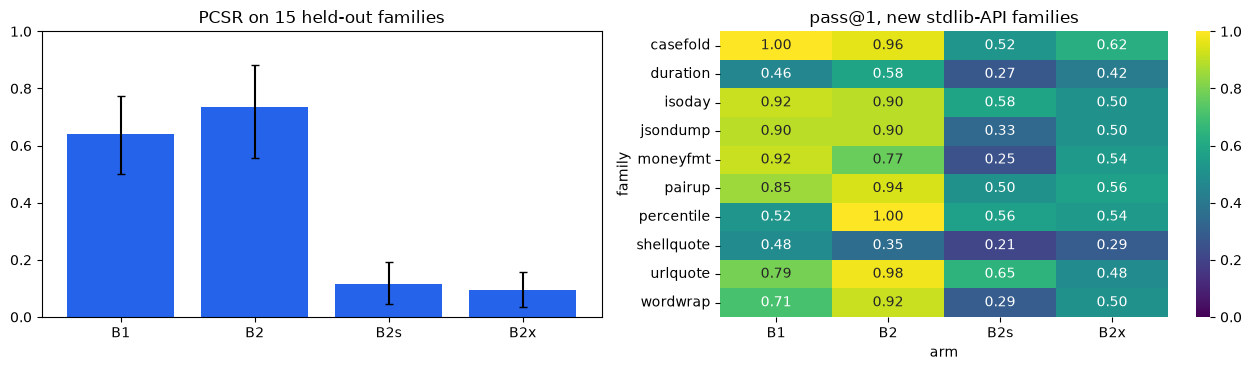

In [20]:
NEWF = Path("data/tasks/new_families.txt").read_text().strip()
if RUN["rerun_new_families"]:
    ensure_server()
    with bench("arms:new_families_main", "inference", RUN_DIR): sh(f"-m coevo.run_arm --kind synthetic --arms B1,B2,B2s,B2x,B3,B4,B4c --k 2 --families {NEWF} --out runs/new_families_main.jsonl", "logs/new_families_main.log")
    from coevo import rescore
    with bench("lenient_rescore_new", "verification", RUN_DIR): rescore.main(["new_families_main"])
dfx, dfx_s = load_results("runs/lenient/new_families_main.jsonl"), load_results("runs/new_families_main.jsonl")
dfa = pd.concat([df, dfx], ignore_index=True)
print("new-family rollouts:", dfx.groupby("arm").size().to_dict(), "| families:", dfx.family.nunique(), "| pairs:", dfx.pair_id.nunique(), "| pooled held-out families:", dfa.family.nunique())
ORDER_X = ["B1", "B2", "B2s", "B2x"]
TAB_X = {"new families (lenient)": arm_summary(dfx, ORDER_X).set_index("arm"), "all 15 held-out families (lenient)": arm_summary(dfa, ORDER_X).set_index("arm"), "new families (strict)": arm_summary(dfx_s, ORDER_X).set_index("arm")}
for k_, v_ in TAB_X.items(): print("\n" + k_); print(v_[["n_rollouts", "pass@1", "PCSR", "PCSR_lo", "PCSR_hi", "wrong_contract", "applied"]].round(3).to_string())
rows = []
for scope, d_ in (("old 5 families", df), ("new 10 families", dfx), ("all 15 families", dfa)):
    for a, b, note in comps:
        if a not in set(d_.arm) or b not in set(d_.arm): continue
        pa, pb = pair_level(d_, a), pair_level(d_, b); d = cluster_bootstrap_diff(pa, pb); m = mcnemar(pa, pb); se = (d["ci_hi"] - d["ci_lo"]) / (2 * 1.96)
        rows.append({"scope": scope, "A": a, "B": b, "what": note, "dPCSR": d["diff"], "CI_lo": d["ci_lo"], "CI_hi": d["ci_hi"], "pairs": d["n_pairs"], "families": d["n_clusters"], "McNemar_p": m["p_value"], "MDE_80pct_power": 2.8 * se})
ARM_TESTS_X = pd.DataFrame(rows); print("\n" + ARM_TESTS_X.round(3).to_string(index=False))
def wc_level(d_, arm): return d_[d_.arm == arm].groupby(["pair_id", "family"], as_index=False).wrong_contract.mean().rename(columns={"wrong_contract": "wc"})
SEC = []
for a_, b_ in (("B1", "B2"), ("B0", "B2")):
    if a_ not in set(dfa.arm): continue
    d_ = cluster_bootstrap_diff(wc_level(dfa, a_), wc_level(dfa, b_), col="wc"); SEC.append({"endpoint": f"wrong-contract rate, {a_} minus {b_} (secondary, exploratory)", "diff": d_["diff"], "CI_lo": d_["ci_lo"], "CI_hi": d_["ci_hi"], "pairs": d_["n_pairs"], "families": d_["n_clusters"]})
SEC = pd.DataFrame(SEC); print("\n" + SEC.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); t_ = TAB_X["all 15 held-out families (lenient)"].loc[ORDER_X]
ax[0].bar(ORDER_X, t_.PCSR, yerr=[t_.PCSR - t_.PCSR_lo, t_.PCSR_hi - t_.PCSR], color="#2563eb", capsize=3); ax[0].set_title("PCSR on 15 held-out families"); ax[0].set_ylim(0, 1)
sns.heatmap(dfx.pivot_table(index="family", columns="arm", values="resolved", aggfunc="mean")[ORDER_X], annot=True, fmt=".2f", cmap="viridis", ax=ax[1], vmin=0, vmax=1); ax[1].set_title("pass@1, new stdlib-API families"); plt.tight_layout(); plt.show()

On the 10 new families (480 rollouts per arm) lenient PCSR is 0.588 for B1, 0.708 for B2, 0.071 for B2s and 0.083 for B2x. Pooled over all 15 held-out families (180 pairs, 840 rollouts per arm) it is 0.642 (95% CI 0.501 to 0.774) for B1, 0.735 (0.557 to 0.883) for B2, 0.114 for B2s and 0.093 for B2x. B2 minus B2s is +0.621 (0.469 to 0.759) and B2 minus B2x is +0.643 (0.479 to 0.790); both intervals exclude 0 in the original 5 families and in the 10 new ones taken alone (+0.638 and +0.625). B2 also never writes a wrong-contract patch (0.000 over 840 rollouts), where B1 does in 2.9%.

### 4.6 Where the controls lose

Three panels on set 1 (lenient): PCSR with family-clustered intervals, the wrong-contract rate, and pass@1 per family and arm. `cls` gives each rollout exactly one label, in this order: resolved, not applied, wrong contract, regression, wrong behaviour.

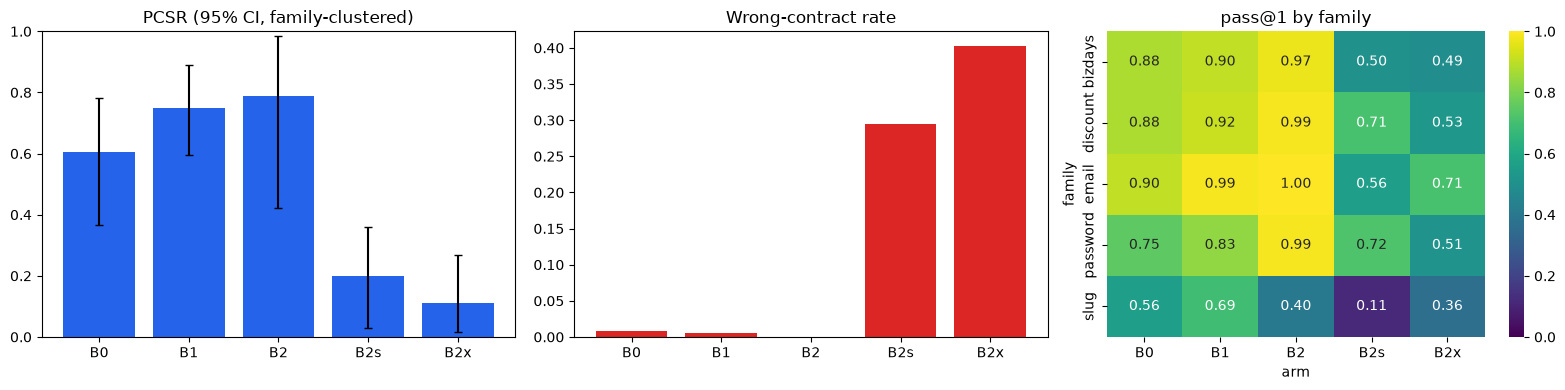

outcome  resolved  wrong behaviour  wrong contract  regression  not applied
arm                                                                        
B0          0.792            0.075           0.008       0.022        0.103
B1          0.867            0.075           0.006       0.025        0.028
B2          0.869            0.119           0.000       0.000        0.011
B2s         0.519            0.164           0.294       0.003        0.019
B2x         0.519            0.058           0.403       0.003        0.017


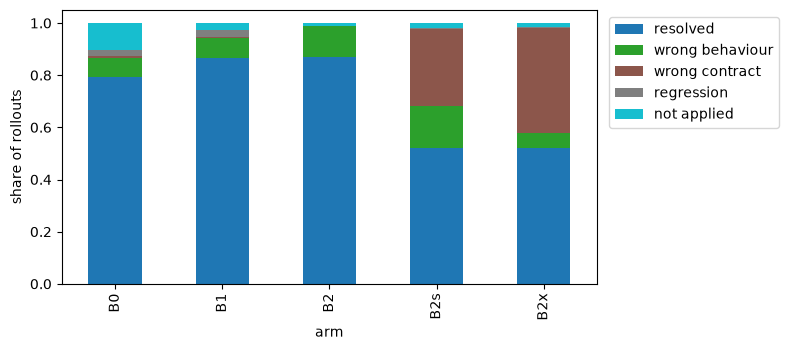

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4)); t = tab.loc[ORDER]
ax[0].bar(ORDER, t.PCSR, yerr=[t.PCSR - t.PCSR_lo, t.PCSR_hi - t.PCSR], color="#2563eb", capsize=3); ax[0].set_title("PCSR (95% CI, family-clustered)"); ax[0].set_ylim(0, 1)
ax[1].bar(ORDER, t.wrong_contract, color="#dc2626"); ax[1].set_title("Wrong-contract rate")
sns.heatmap(df.pivot_table(index="family", columns="arm", values="resolved", aggfunc="mean")[ORDER], annot=True, fmt=".2f", cmap="viridis", ax=ax[2], vmin=0, vmax=1); ax[2].set_title("pass@1 by family"); plt.tight_layout(); plt.show()
def cls(r):
    if r.resolved: return "resolved"
    if not r.applied: return "not applied"
    if r.wrong_contract: return "wrong contract"
    if not r.inv_pass: return "regression"
    return "wrong behaviour"
df["outcome"] = df.apply(cls, axis=1)
tx = df.groupby(["arm", "outcome"]).size().unstack(fill_value=0).reindex(ORDER); tx = tx.div(tx.sum(1), axis=0)[["resolved", "wrong behaviour", "wrong contract", "regression", "not applied"]]
print(tx.round(3).to_string()); tx.plot.bar(stacked=True, figsize=(8, 3.6), colormap="tab10"); plt.ylabel("share of rollouts"); plt.legend(bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

Three panels and a table of label shares per arm, 360 rollouts each. The resolved share is 0.869 for B2 and 0.519 for both controls. The gap is wrong-contract patches: 0.294 for B2s and 0.403 for B2x against 0.000 for B2. Not-applied shares stay between 0.011 and 0.019 for the three arms, so the controls lose on contract, not on format. B2 has no regressions either (0.000, against 0.025 for B1), and its remaining misses are wrong behavior (0.119) inside the right contract.

### 4.7 What each arm costs

The cost ledger is parsed from the `ledger:` line in `logs/main_synth_test.log`. It records calls and tokens per arm.

In [22]:
led = None
for line in open("logs/main_synth_test.log"):
    if line.startswith("ledger:"): led = json.loads(line.split("ledger:", 1)[1])
cost_arm = pd.DataFrame(led).T; cost_arm["tokens_per_call"] = (cost_arm.prompt_tokens + cost_arm.completion_tokens) / cost_arm.calls; cost_arm.index = [i.split(":")[0] for i in cost_arm.index]
print(cost_arm.loc[[a for a in ORDER if a in cost_arm.index]].round(1).to_string())


      calls  prompt_tokens  completion_tokens  latency_s  tokens_per_call
B0   1872.0      2147586.0           637158.0    81087.7           1487.6
B1   1671.0      1924517.0           307988.0    40595.2           1336.0
B2   1346.0      1833053.0           318446.0    41066.3           1598.4
B2s  1287.0      1804340.0           344523.0    44713.9           1669.7


Decision records answer questions the agent would otherwise search for. B2 makes 1,346 calls against 1,872 for B0 and 1,671 for B1, 28% and 19% fewer, and sends 1.83 million prompt tokens against 2.15 million and 1.92 million. B0 also spends about twice the summed latency (81,087.7 s against 40,595 to 44,714 s for the other arms), which includes queueing.

## Section 5. Experiment 2 (RQ2): predicting patch success before running the patch

Evidence decides which contract the agent follows. The next question is whether a model can tell, before a patch is executed, that it honours the contract in force. 6,480 executed interventions give the labels. The contract-conditioned model B8 reaches AUPRC 0.410 against 0.217 for its contract-blind twin B7, and 0.131 when it is handed another task's contract.

### 5.1 Executed interventions

`coevo/wm_data.py` runs 27 candidates per task in fresh sandboxes: the task's own reference, the other contract's reference, a no-op and 24 AST mutants. The labels are the verifier's outcomes, not model judgments. The cell executes 12 tasks live, then loads `runs/wm_interventions.jsonl`.

In [23]:
from coevo.wm_data import run_task
from concurrent.futures import ThreadPoolExecutor
live_tasks = store.tasks("synthetic")[:12]
with bench("interventions_live_12x27", "verification", RUN_DIR) as b:
    with ThreadPoolExecutor(8) as ex:
        live = [r for rws in ex.map(run_task, [(store, t, store.synth[t.pair_id], 24, 11) for t in live_tasks]) for r in rws]
print(f"executed {len(live)} interventions live in {b['wall_s']:.0f}s ({len(live) / b['wall_s']:.1f} verifications/s)")
dl = pd.DataFrame([{"origin": r["origin"].split("_")[0] + ("_" + r["origin"].split("_")[1] if r["origin"].startswith("reference") else ""), "own": r["cert"]["own_pass"], "inv": r["cert"]["p2p_pass"], "other": r["cert"]["other_contract_pass"]} for r in live])
print(dl.groupby("origin").agg(n=("own", "size"), own_pass=("own", "mean"), invariants=("inv", "mean"), other_contract=("other", "mean")).round(2).to_string())
if RUN["regen_interventions"]:
    from coevo.wm_data import main as gen_wm
    with bench("interventions_full", "verification", RUN_DIR): gen_wm("runs/wm_interventions.jsonl")
full_iv = [json.loads(l) for l in open("runs/wm_interventions.jsonl")]
print("\nfull dataset:", len(full_iv), "interventions | resolved:", sum(r["resolved"] for r in full_iv), f"({np.mean([r['resolved'] for r in full_iv]):.1%}) | own-contract pass {np.mean([r['cert']['own_pass'] for r in full_iv]):.1%} | invariants pass {np.mean([r['cert']['p2p_pass'] for r in full_iv]):.1%}")

executed 324 interventions live in 38s (8.4 verifications/s)
                   n  own_pass  invariants  other_contract
origin                                                    
mutant           288      0.38         0.4            0.38
noop              12      0.00         1.0            0.00
reference_other   12      0.00         1.0            1.00
reference_own     12      1.00         1.0            0.00



full dataset: 6480 interventions | resolved: 486 (7.5%) | own-contract pass 10.5% | invariants pass 45.9%


A live batch of 12 tasks gives 324 interventions in 38 s (8.4 verifications per second), and the stored set is then summarised. In the batch the task's own reference passes its own tests (1.00) and fails the other contract's; the other contract's reference does the reverse (own 0.00, other 1.00); the no-op passes neither. The 288 mutants pass their own tests at 0.38. The stored set has 6,480 rows with 486 resolved (7.5%), own-contract pass 10.5% and invariants pass 45.9%. The verifier separates the two contracts exactly: the two references swap pass and fail.

### 5.2 What the models see

`coevo/worldmodel.py` builds three feature groups per patch: S (12 structural values), T (64 hashed added-line tokens) and C (7 contract-alignment values that compare the patch with the contract in force). B6 uses S, B7 adds T, and B8 adds C. The table shows the mean of each C feature by outcome.

In [24]:
from coevo.wm_eval import load_samples, cv_predict, cluster_bootstrap, metrics_by_family, selection_eval, shuffle_contracts, FAMILIES
from coevo.worldmodel import contract_features, structural_features, featurize, make_model, head_metrics, HEADS
WS = load_samples("runs/wm_interventions.jsonl")
cf = np.array([contract_features(s) for s in WS]); y_res = np.array([s.labels["resolved"] for s in WS]); y_own = np.array([s.labels["own_pass"] for s in WS])
names = ["gov_numbers_realised", "added_numbers_justified", "added_numbers_only_in_other_contract", "gov_tokens_realised", "added_tokens_in_gov", "added_tokens_only_in_other", "gov_numbers_missing"]
print(pd.DataFrame({"feature": names, "mean | resolved": cf[y_res == 1].mean(0), "mean | not resolved": cf[y_res == 0].mean(0), "mean | own_pass": cf[y_own == 1].mean(0), "mean | not own_pass": cf[y_own == 0].mean(0)}).round(3).to_string(index=False))
print("samples:", len(WS), "| structural dims:", len(structural_features(WS[0])), "+ 64 hashed text + 7 contract dims")

                             feature  mean | resolved  mean | not resolved  mean | own_pass  mean | not own_pass
                gov_numbers_realised            0.194                0.132            0.164                0.133
             added_numbers_justified            0.503                0.193            0.448                0.189
added_numbers_only_in_other_contract            0.007                0.058            0.006                0.060
                 gov_tokens_realised            0.268                0.271            0.267                0.271
                 added_tokens_in_gov            0.218                0.214            0.221                0.214
          added_tokens_only_in_other            0.001                0.011            0.000                0.011
                 gov_numbers_missing            3.996                4.520            4.173                4.517
samples: 6480 | structural dims: 12 + 64 hashed text + 7 contract dims


The numeric contract features separate the outcomes: `added_numbers_justified` averages 0.503 for resolved patches and 0.193 for unresolved ones, and `added_numbers_only_in_other_contract` averages 0.007 against 0.058. Token-level overlap barely moves (`gov_tokens_realised` 0.268 against 0.271). The C group therefore carries information that S and T do not, namely whether the constants in a patch come from the contract in force. The last line gives the three dimensions: 12, 64 and 7.

### 5.3 Family-disjoint cross-validation and the shuffled-contract control

`cv_predict` in `coevo/wm_eval.py` holds out 2 of the 10 families per fold, so every prediction is for a family the model never saw. Metrics are AUPRC, Brier score and ECE with a family bootstrap. B8-shuffled uses the trained B8 but gives each test task another task's contract, which tests whether B8 reads the contract or just benefits from extra features.

In [25]:
MODELS = ["B5", "B6", "B7", "B8", "B8m", "B8g"]
P = {}
for n in MODELS:
    with bench(f"wm_cv:{n}", "world_model", RUN_DIR) as b: P[n] = cv_predict(n, WS)
    print(f"{n}: 5-fold family-disjoint fit+predict in {b['wall_s']:.1f}s (GPU util mean {b['gpu_util_mean']:.0f}%)")
P["B8-shuffled"] = cv_predict("B8", WS, eval_samples=shuffle_contracts(WS))
rows = []
for n, p in P.items():
    for head in HEADS:
        for metric in ("auprc", "brier", "ece"):
            per_fam = metrics_by_family(WS, p, head, metric); m, lo, hi = cluster_bootstrap(per_fam, seed=1) if per_fam else (np.nan,) * 3
            rows.append({"model": n, "head": head, "metric": metric, "mean": m, "lo": lo, "hi": hi})
R = pd.DataFrame(rows)
for head in HEADS:
    t_ = R[R["head"] == head].pivot(index="model", columns="metric", values="mean").loc[list(P)]
    print(f"\nhead = {head} (base rate {np.mean([s.labels[head] for s in WS]):.3f})"); print(t_[["auprc", "brier", "ece"]].round(3).to_string())
print("\nAUPRC(resolved), family-bootstrap 95% CI:"); print(R[(R["head"] == "resolved") & (R.metric == "auprc")].set_index("model")[["mean", "lo", "hi"]].round(3).to_string())

B5: 5-fold family-disjoint fit+predict in 0.2s (GPU util mean 0%)


B6: 5-fold family-disjoint fit+predict in 1.5s (GPU util mean 0%)


B7: 5-fold family-disjoint fit+predict in 4.1s (GPU util mean 0%)


B8: 5-fold family-disjoint fit+predict in 7.0s (GPU util mean 0%)


B8m: 5-fold family-disjoint fit+predict in 9.4s (GPU util mean 0%)


B8g: 5-fold family-disjoint fit+predict in 14.2s (GPU util mean 8%)



head = own_pass (base rate 0.105)
metric       auprc  brier    ece
model                           
B5           0.162  0.209  0.335
B6           0.219  0.098  0.083
B7           0.244  0.094  0.073
B8           0.382  0.092  0.093
B8m          0.327  0.120  0.122
B8g          0.324  0.169  0.172
B8-shuffled  0.163  0.103  0.094

head = inv_pass (base rate 0.459)
metric       auprc  brier    ece
model                           
B5           0.651  0.246  0.215
B6           0.571  0.387  0.389
B7           0.742  0.345  0.375
B8           0.746  0.329  0.358
B8m          0.701  0.405  0.414
B8g          0.671  0.480  0.483
B8-shuffled  0.747  0.329  0.354

head = resolved (base rate 0.075)
metric       auprc  brier    ece
model                           
B5           0.149  0.203  0.365
B6           0.205  0.070  0.057
B7           0.217  0.070  0.055
B8           0.410  0.060  0.058
B8m          0.208  0.103  0.125
B8g          0.326  0.134  0.141
B8-shuffled  0.131  0.074  0.069

AUP

The base rate for `resolved` is 0.075. AUPRC for `resolved`: B8 0.410 (95% CI 0.267 to 0.570), B7 0.217 (0.144 to 0.294), B6 0.205 and B5 0.149. B8-shuffled falls to 0.131 (0.090 to 0.172), below B7. The paired gain of B8 over B7 is +0.194 (0.116 to 0.284) and over the shuffled control +0.279 (0.152 to 0.426). The conditioning information has to be the right contract to help, so the model is using the contract in force.

### 5.4 Choosing among candidates without executing them

`selection_eval` draws 30 random pools of K executed candidates per task (K = 4, 8, 16), and the model picks the candidate with the highest predicted P(resolved), using out-of-fold predictions. A pick scores 1 if it truly resolves. A random pick is the baseline.

K          4      8      16
policy                     
B5      0.390  0.259  0.135
B6      0.472  0.374  0.307
B7      0.413  0.356  0.343
B8      0.603  0.501  0.495
B8g     0.527  0.454  0.428
B8m     0.521  0.383  0.300

K=8 with family-bootstrap 95% CI:
policy  selected_success    lo    hi
    B5             0.259 0.165 0.348
    B6             0.374 0.238 0.502
    B7             0.356 0.218 0.498
    B8             0.501 0.343 0.630
   B8m             0.383 0.256 0.520
   B8g             0.454 0.295 0.649
random-pick success by K: {4: 0.278, 8: 0.157, 16: 0.099}


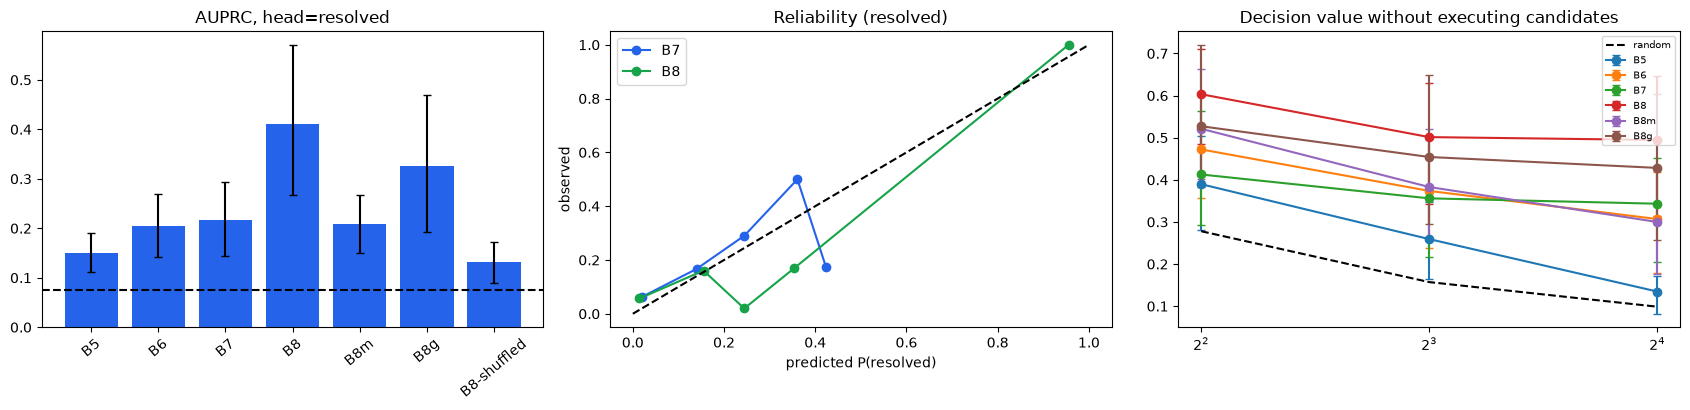

In [26]:
rr = R[(R["head"] == "resolved") & (R.metric == "auprc")].set_index("model").loc[list(P)]
rows = []
for K in (4, 8, 16):
    for n in MODELS:
        e = selection_eval(WS, P[n]["resolved"], pool_size=K, pools_per_task=30, seed=3); m, lo, hi = cluster_bootstrap(e["per_family"], seed=2)
        rows.append({"K": K, "policy": n, "selected_success": e["selected_success"], "lo": lo, "hi": hi, "random_pick": e["random_success"], "pools": e["n_pools"]})
SEL = pd.DataFrame(rows); print(SEL.pivot(index="policy", columns="K", values="selected_success").round(3).to_string())
print("\nK=8 with family-bootstrap 95% CI:"); print(SEL[SEL.K == 8][["policy", "selected_success", "lo", "hi"]].round(3).to_string(index=False))
print("random-pick success by K:", SEL.drop_duplicates("K").set_index("K").random_pick.round(3).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].bar(rr.index, rr["mean"], yerr=[rr["mean"] - rr.lo, rr.hi - rr["mean"]], capsize=3, color="#2563eb"); ax[0].axhline(y_res.mean(), ls="--", c="k"); ax[0].set_title("AUPRC, head=resolved"); ax[0].tick_params(axis="x", rotation=40)
for n, c in (("B7", "#2563eb"), ("B8", "#16a34a")):
    p_ = P[n]["resolved"]; idx = np.digitize(p_, np.linspace(0, 1, 11)[1:-1]); xs, ys = [], []
    for b_ in range(10):
        m_ = idx == b_
        if m_.sum() >= 20: xs.append(p_[m_].mean()); ys.append(y_res[m_].mean())
    ax[1].plot(xs, ys, "o-", label=n, c=c)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("predicted P(resolved)"); ax[1].set_ylabel("observed"); ax[1].legend(); ax[1].set_title("Reliability (resolved)")
for n in MODELS:
    d = SEL[SEL.policy == n]; ax[2].errorbar(d.K, d.selected_success, yerr=[d.selected_success - d.lo, d.hi - d.selected_success], marker="o", label=n, capsize=3)
ax[2].plot(SEL.drop_duplicates("K").K, SEL.drop_duplicates("K").random_pick, "k--", label="random"); ax[2].set_xscale("log", base=2); ax[2].legend(fontsize=7); ax[2].set_title("Decision value without executing candidates"); plt.tight_layout(); plt.show()

B8 picks a resolving candidate 0.603, 0.501 and 0.495 of the time at K = 4, 8 and 16, against random picks of 0.278, 0.157 and 0.099. At K = 8 the other models reach 0.356 (B7), 0.374 (B6) and 0.259 (B5). The paired gain of B8 over B7 is 0.129 (0.054 to 0.220). At K = 8 this means B8 finds a working patch about three times as often as a random pick, without running any of the candidates.

### 5.5 The shuffled control, and patches written by Gemma 4

Part 1 tabulates the shuffled control in the same decision setting. Part 2 refits B5 to B8 on the 3,240 training-family interventions with `fit_world_models` and scores the 1,440 real Gemma 4 patches in `runs/main_synth_test.jsonl`, looking at ranking quality among the patches that applied. Unchanged code cannot resolve, so the applied subset is where a model has to read the patch.

In [27]:
e8 = {n: selection_eval(WS, P[n]["resolved"], pool_size=8, pools_per_task=30, seed=3) for n in ["B7", "B8", "B8-shuffled"]}
print(pd.DataFrame({n: {"AUPRC(resolved)": R[(R.model == n) & (R["head"] == "resolved") & (R.metric == "auprc")]["mean"].iloc[0], "Brier(resolved)": R[(R.model == n) & (R["head"] == "resolved") & (R.metric == "brier")]["mean"].iloc[0], "select@8": e8[n]["selected_success"]} for n in e8}).T.round(3).to_string())
from coevo.b9_eval import fit_world_models, to_sample, TRAIN_FAMILIES, rollouts_to_samples
from sklearn.metrics import roc_auc_score
wms, n_train = fit_world_models("runs/wm_interventions.jsonl"); wms["B6"] = make_model("B6").fit([s for s in WS if s.family in TRAIN_FAMILIES]); wms["B5"] = make_model("B5")
tasks_by_id = {t.task_id: t for t in store.tasks("synthetic")}
llm_rows = [r for r in map(json.loads, open("runs/main_synth_test.jsonl")) if r["arm"] in ("B1", "B2", "B2s", "B4")]; ctx = {}
llm_samples = [to_sample(store, tasks_by_id[r["task_id"]], r["text"], ctx, {"own_pass": int(r["cert"]["own_pass"]), "inv_pass": int(r["cert"]["p2p_pass"]), "resolved": int(r["resolved"])}) for r in llm_rows]
y_llm = np.array([s.labels["resolved"] for s in llm_samples]); applied = np.array([r["cert"]["applied"] for r in llm_rows], dtype=bool)
print(f"\nLLM patches scored: {len(llm_samples)} | resolved rate {y_llm.mean():.3f} | {n_train} training interventions | share not applied: {1 - applied.mean():.3f} (unchanged code, cannot resolve)")
out = {}
for n, m in wms.items():
    pr = m.predict(llm_samples)["resolved"]; mm = head_metrics(y_llm, pr); out[n] = {"AUPRC": mm["auprc"], "AUROC": mm["auroc"], "Brier": mm["brier"], "ECE": mm["ece"], "AUROC_applied_only": roc_auc_score(y_llm[applied], pr[applied])}
print("ranking quality among the patches that applied (", int(applied.sum()), "of", len(applied), "), trained on executed interventions only:"); print(pd.DataFrame(out).T[["AUROC_applied_only"]].round(3).to_string())


             AUPRC(resolved)  Brier(resolved)  select@8
B7                     0.217            0.070     0.356
B8                     0.410            0.060     0.501
B8-shuffled            0.131            0.074     0.238



LLM patches scored: 1440 | resolved rate 0.533 | 3240 training interventions | share not applied: 0.326 (unchanged code, cannot resolve)


ranking quality among the patches that applied ( 971 of 1440 ), trained on executed interventions only:
    AUROC_applied_only
B7               0.615
B8               0.761
B6               0.508
B5               0.638


The control table repeats the result of 5.3 in the decision setting: shuffled B8 reaches select@8 of 0.238, against 0.501 for B8 and 0.356 for B7. On the 1,440 real Gemma 4 patches (resolve rate 0.533, 32.6% not applied), the contract-conditioned model ranks the patches that did apply best: AUROC 0.761 for B8, against 0.615 for B7, 0.508 for B6 and 0.638 for B5. Among patches that actually change the code, the contract features add ranking quality that structure and tokens do not (point estimates, one seed).

### 5.6 GPU against CPU for the world model

`bench` times fit, feature extraction and forward pass on the 3,240 training interventions for the B7 and B8 trees (CPU), the B8m MLP (CPU) and B8g, a CUDA MLP from `coevo/worldmodel_gpu.py`.

In [28]:
import torch
sub = [s for s in WS if s.family in TRAIN_FAMILIES]; rows = []
for n in ("B7", "B8", "B8m", "B8g"):
    with bench(f"wm_fit:{n}", "world_model", RUN_DIR) as b: m_ = make_model(n).fit(sub)
    rows.append({"model": n, "device": "cuda" if n == "B8g" else "cpu", "fit_s": b["wall_s"], "gpu_util_mean": b["gpu_util_mean"], "energy_wh": b["energy_wh"]})
    if n == "B8": gb = m_
    if n == "B8g": mg = m_
t0 = time.time(); X4k = featurize(sub[:4096] if len(sub) >= 4096 else sub, "STC"); feat_ms = (time.time() - t0) / len(X4k) * 1000
def timeit(fn, reps=20):
    fn(); t = time.time()
    for _ in range(reps): fn()
    return (time.time() - t) / reps * 1000
Xg = torch.tensor(mg.scaler.transform(X4k), dtype=torch.float32, device="cuda")
cpu_ms = timeit(lambda: [m.predict_proba(X4k)[:, 1] for m in gb.models.values() if not isinstance(m, float)])
gpu_ms = timeit(lambda: (torch.sigmoid(mg.net(Xg)), torch.cuda.synchronize()))
print(pd.DataFrame(rows).round(3).to_string(index=False))
WMBENCH = {"patches": len(X4k), "feature_extraction_ms_per_patch_cpu": feat_ms, "gbdt_forward_ms_per_batch_cpu": cpu_ms, "cuda_mlp_forward_ms_per_batch": gpu_ms}
print({k: round(v, 3) if isinstance(v, float) else v for k, v in WMBENCH.items()})

model device  fit_s  gpu_util_mean  energy_wh
   B7    cpu   0.54            0.0      0.000
   B8    cpu   0.87            0.0      0.000
  B8m    cpu   1.11            0.0      0.000
  B8g   cuda   1.63            0.0      0.005
{'patches': 3240, 'feature_extraction_ms_per_patch_cpu': 0.186, 'gbdt_forward_ms_per_batch_cpu': 4.346, 'cuda_mlp_forward_ms_per_batch': 0.049}


Fitting the four models on the 3,240 training interventions takes 0.54 s (B7), 0.87 s (B8), 1.11 s (B8m) and 1.63 s (B8g, on the GPU). Feature extraction costs 0.186 ms per patch on CPU, and a forward pass over a batch takes 4.35 ms for the tree ensemble and 0.049 ms for the CUDA MLP, about 89 times faster. Scoring a candidate patch costs well under a millisecond, small next to generating it.

### 5.7 A graph-attention variant and the graph-delta head

`coevo/worldmodel_gat.py` is a graph-attention network over patch, symbol, caller, test and contract nodes, run with 3 seeds. B7a is the same network without contract nodes. A second head predicts which callers and tests fail. Stored results load unless `RUN["rerun_gat"]` is set.

no-skill AUPRC (base rate of resolved): 0.075
       model  AUPRC(resolved)    lo    hi  Brier   ECE  runs
          B7            0.217 0.144 0.294  0.070 0.055     1
          B8            0.410 0.267 0.570  0.060 0.058     1
         B7a            0.165 0.117 0.217  0.103 0.132     3
         B8a            0.281 0.175 0.388  0.165 0.178     3
 B8-shuffled            0.131 0.090 0.172  0.074 0.069     1
B8a-shuffled            0.091 0.064 0.123  0.099 0.103     3

paired AUPRC(resolved) differences (family-clustered bootstrap):
        comparison   diff  ci_lo  ci_hi
          B8a - B8 -0.130 -0.230 -0.037
         B8a - B7a  0.116  0.019  0.220
          B7a - B7 -0.052 -0.138  0.023
           B8 - B7  0.194  0.116  0.284
B8a - B8a-shuffled  0.189  0.095  0.295

graph-delta head (which caller/test nodes are affected), labelled nodes: 38880
                     model  test-node AUPRC    lo    hi
                       B7a            0.484 0.322 0.661
                       B8a   

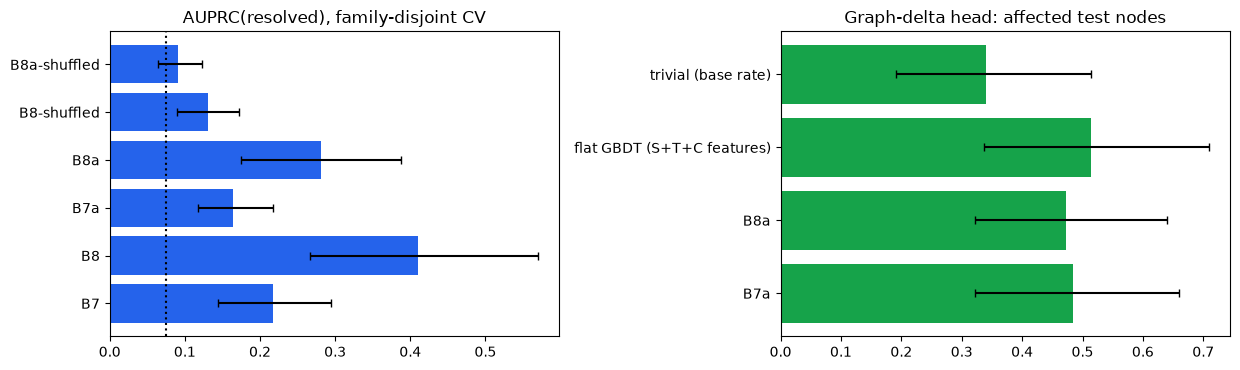

In [29]:
if RUN["rerun_gat"]:
    with bench("wm_graph_attention_cv", "world_model", RUN_DIR) as b: sh("-m coevo.worldmodel_gat --cv", "logs/wm_gat.log")
GATJ = json.load(open("runs/wm_gat_results.json"))
rows = []
for m_ in ("B5", "B6", "B7", "B8", "B7a", "B8a", "B8-shuffled", "B8a-shuffled"):
    if m_ not in GATJ["models"]: continue
    r_ = GATJ["models"][m_]["resolved"]; rows.append({"model": m_, "AUPRC(resolved)": r_["auprc"]["seed_averaged_mean"], "lo": r_["auprc"]["ci_lo"], "hi": r_["auprc"]["ci_hi"], "Brier": r_["brier"]["seed_averaged_mean"], "ECE": r_["ece"]["seed_averaged_mean"], "runs": GATJ["models"][m_]["n_runs"]})
GATTAB = pd.DataFrame(rows); print("no-skill AUPRC (base rate of resolved):", round(GATJ["base_rate"]["resolved"], 3)); print(GATTAB.round(3).to_string(index=False))
GATD = pd.DataFrame([{"comparison": k, **v} for k, v in GATJ["auprc_resolved_differences"].items()]); print("\npaired AUPRC(resolved) differences (family-clustered bootstrap):"); print(GATD.round(3).to_string(index=False))
dl = GATJ["delta"]; DELTA = pd.DataFrame([{"model": m_, "test-node AUPRC": dl[m_]["test_nodes"]["auprc"]["seed_averaged"][0], "lo": dl[m_]["test_nodes"]["auprc"]["seed_averaged"][1], "hi": dl[m_]["test_nodes"]["auprc"]["seed_averaged"][2]} for m_ in ("B7a", "B8a")] +
                     [{"model": "flat GBDT (S+T+C features)", "test-node AUPRC": dl["flat_gbdt_STC"]["test_nodes"]["auprc"][0], "lo": dl["flat_gbdt_STC"]["test_nodes"]["auprc"][1], "hi": dl["flat_gbdt_STC"]["test_nodes"]["auprc"][2]},
                      {"model": "trivial (base rate)", "test-node AUPRC": dl["trivial"]["test_nodes"]["base_rate"][0], "lo": dl["trivial"]["test_nodes"]["base_rate"][1], "hi": dl["trivial"]["test_nodes"]["base_rate"][2]}])
print("\ngraph-delta head (which caller/test nodes are affected), labelled nodes:", dl["B8a"]["n_labelled_nodes"]); print(DELTA.round(3).to_string(index=False))
GAT_ROWS = [("H2 (graph attention)", "B8a contract-conditioned vs B7a same graph net without contract", GATJ["auprc_resolved_differences"]["B8a - B7a"]["diff"], GATJ["auprc_resolved_differences"]["B8a - B7a"]["ci_lo"], GATJ["auprc_resolved_differences"]["B8a - B7a"]["ci_hi"], "AUPRC(resolved)"),
            ("H2 control (graph attention)", "B8a vs B8a-shuffled contract", GATJ["auprc_resolved_differences"]["B8a - B8a-shuffled"]["diff"], GATJ["auprc_resolved_differences"]["B8a - B8a-shuffled"]["ci_lo"], GATJ["auprc_resolved_differences"]["B8a - B8a-shuffled"]["ci_hi"], "AUPRC(resolved)"),
            ("architecture comparison", "B8a graph attention vs B8 GBDT", GATJ["auprc_resolved_differences"]["B8a - B8"]["diff"], GATJ["auprc_resolved_differences"]["B8a - B8"]["ci_lo"], GATJ["auprc_resolved_differences"]["B8a - B8"]["ci_hi"], "AUPRC(resolved)")]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8)); g_ = GATTAB.set_index("model"); ax[0].barh(g_.index, g_["AUPRC(resolved)"], xerr=[g_["AUPRC(resolved)"] - g_.lo, g_.hi - g_["AUPRC(resolved)"]], color="#2563eb", capsize=3); ax[0].axvline(GATJ["base_rate"]["resolved"], ls=":", c="k"); ax[0].set_title("AUPRC(resolved), family-disjoint CV")
d_ = DELTA.set_index("model"); ax[1].barh(d_.index, d_["test-node AUPRC"], xerr=[d_["test-node AUPRC"] - d_.lo, d_.hi - d_["test-node AUPRC"]], color="#16a34a", capsize=3); ax[1].set_title("Graph-delta head: affected test nodes"); plt.tight_layout(); plt.show()

Conditioning on the contract helps in a second architecture as well. The graph network with contract nodes (B8a) reaches AUPRC 0.281 (95% CI 0.175 to 0.388). It beats the same network without contract nodes (B7a) by 0.116 (0.019 to 0.220) and its own shuffled-contract version by 0.189 (0.095 to 0.295). The gradient-boosted B8, at 0.410, remains the strongest model, so the contract signal is architecture-independent and trees are the efficient way to use it here. The graph-delta head scores 38,880 labelled nodes; its test-node AUPRC is 0.473 for B8a against a base rate of 0.340.

## Section 6. Experiment 3 (RQ3): verified outcomes flowing back into the agent

The evidence ledger keeps every verified outcome. Two ways of using them run on the same device. Verified-witness memory puts a verified earlier fix into the prompt as context, and LoRA adaptation trains on verified edits, first by supervised fine-tuning and then with execution-rewarded RL.

### 6.1 Verified-witness memory

B10 adds a verified version-0 diff, flagged as superseded, to the version-1 prompt. B10u adds the same diff without the flag, as a control. Both are compared with B2 on the same version-1 tasks.

In [30]:
if RUN["rerun_b10"]:
    ensure_server()
    with bench("b10_verified_memory", "inference", RUN_DIR): sh("-m coevo.b10", "logs/b10.log")
b10df = load_results("runs/lenient/b10.jsonl"); base = df[(df.arm == "B2") & (df.version == 1) & df.task_id.isin(b10df.task_id.unique())]
G10 = pd.concat([base.assign(arm="B2"), b10df]); print(G10.groupby("arm").agg(n=("resolved", "size"), resolved=("resolved", "mean"), wrong_contract=("wrong_contract", "mean"), applied=("applied", "mean")).round(3).to_string())
fam_rate = G10.groupby(["arm", "family"]).resolved.mean().unstack(0); print("\nper-family resolved rate:\n", fam_rate.round(3).to_string())
for b_ in ("B2", "B10u"):
    m_, lo_, hi_ = cluster_bootstrap({k: fam_rate["B10"][k] - fam_rate[b_][k] for k in fam_rate.index}, seed=7); print(f"B10 minus {b_}: {m_:+.3f} (family-clustered 95% CI {lo_:.3f} to {hi_:.3f})")

        n  resolved  wrong_contract  applied
arm                                         
B10   150     0.907             0.0    1.000
B10u  150     0.880             0.0    1.000
B2    150     0.853             0.0    0.993

per-family resolved rate:
 arm         B10   B10u     B2
family                       
bizdays   1.000  0.967  1.000
discount  1.000  1.000  0.970
email     1.000  0.970  1.000
password  1.000  1.000  1.000
slug      0.417  0.333  0.125
B10 minus B2: +0.064 (family-clustered 95% CI 0.000 to 0.181)
B10 minus B10u: +0.029 (family-clustered 95% CI 0.006 to 0.057)


B10 resolves 0.907 of its rollouts, B10u 0.880 and B2 0.853 (150 rollouts each), and the wrong-contract rate is 0.000 in all three. The headroom sits in one family: `slug` goes from 0.125 for B2 to 0.333 for B10u and 0.417 for B10. B10 minus B2 is +0.064 (95% CI 0.000 to 0.181), and B10 minus B10u is +0.029 (0.006 to 0.057). A verified earlier fix works as useful context, and the superseded flag adds the most in the family where there is room to improve.

### 6.2 Supervised and execution-rewarded adaptation on one device

A LoRA (r = 16, all language-model linear layers) is trained on the five training families only. T1 is SFT on verified edits. T2L adds DPO and T3aL adds one round of GRPO-style RL with the execution reward (1.0 resolved, 0.25 own-contract pass, 0.10 invariants, minus a length cost); both use clean labels from the lenient parser. The cell scores each policy on the 60 held-out pairs and reports PCSR, the strict-parser pass@1, the share of edits that applied, turns and wall time per rollout, plus the paired contrast of RL against DPO.

       n_rollouts   PCSR  PCSR_lo  PCSR_hi  pass@1  pass@1 strict  applied  turns   wall_s
model                                                                                     
T0            360  0.789    0.422    0.983   0.869          0.614    0.989  3.739  114.687
T1            360  0.767    0.367    1.000   0.864          0.864    1.000  1.000   20.048
T2L           360  0.478    0.122    0.817   0.681          0.636    0.819  2.211   58.580
T3aL          360  0.756    0.356    1.000   0.844          0.811    1.000  1.222   21.794

   A   B  dPCSR  CI_lo  CI_hi  A_only  B_only  McNemar_p
T3aL T2L  0.278  0.044    0.6      16       0        0.0

adapter  steps  first_loss  last_loss  wall_s  peak_gpu_gb
    sft     19      0.2611     0.0255   627.1         33.2
   sftL     19      0.1616     0.0794   608.7         33.2
   dpoL      6      0.6931     0.3188   353.0          NaN
   rl1L     65      0.0674    -0.1673  2153.5          NaN


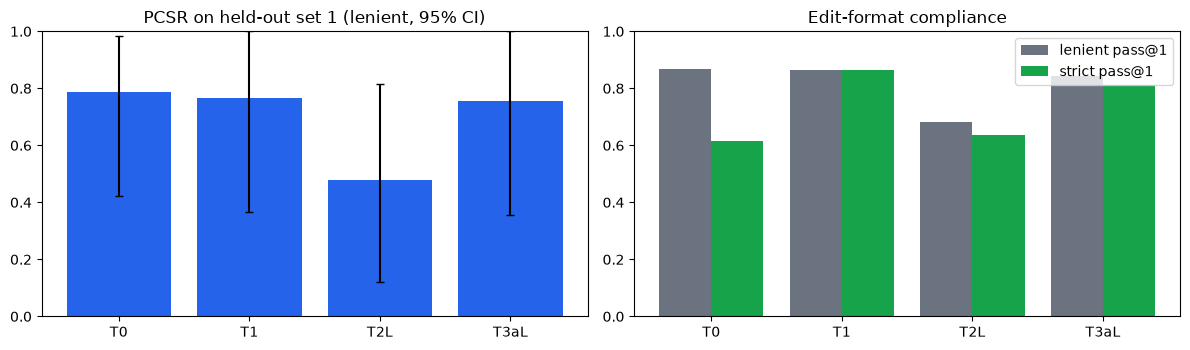

In [31]:
tfiles = {"T0": "runs/lenient/main_synth_test.jsonl", "T1": "runs/lenient/eval_T1.jsonl", "T2L": "runs/lenient/eval_T2L.jsonl", "T3aL": "runs/lenient/eval_T3aL.jsonl"}
dfs = {}
for k, f in tfiles.items():
    d_ = load_results(f); dfs[k] = (d_[d_.arm == "B2"] if k == "T0" else d_).assign(model=k, arm="B2")
TD = pd.concat(dfs.values()); TM = pd.concat([arm_summary(TD, ["B2"], model=k).assign(model=k) for k in dfs]).set_index("model")
def _strict(k, f):
    rs = [r for r in map(json.loads, open(f)) if k != "T0" or r["arm"] == "B2"]
    return np.mean([bool(r["resolved"]) and not bool(r.get("lenient_recovered")) for r in rs])
TM["pass@1 strict"] = [_strict(k, f) for k, f in tfiles.items()]
print(TM[["n_rollouts", "PCSR", "PCSR_lo", "PCSR_hi", "pass@1", "pass@1 strict", "applied", "turns", "wall_s"]].round(3).to_string())
d_ = cluster_bootstrap_diff(pair_level(TD, "B2", "T3aL"), pair_level(TD, "B2", "T2L")); m_ = mcnemar(pair_level(TD, "B2", "T3aL"), pair_level(TD, "B2", "T2L"))
TTEST = pd.DataFrame([{"A": "T3aL", "B": "T2L", "dPCSR": d_["diff"], "CI_lo": d_["ci_lo"], "CI_hi": d_["ci_hi"], "A_only": m_["a_only"], "B_only": m_["b_only"], "McNemar_p": m_["p_value"]}]); print(); print(TTEST.round(3).to_string(index=False))
logs = {n: pd.DataFrame(json.load(open(f"adapters/{n}/train_log.json"))) for n in ("sft", "sftL", "dpoL", "rl1L")}
TRAINLOG = pd.DataFrame([{"adapter": n, "steps": len(d), "first_loss": d.loss.iloc[0], "last_loss": d.loss.iloc[-1], "wall_s": d.sec.iloc[-1], "peak_gpu_gb": d.peak_gb.max() if "peak_gb" in d else np.nan} for n, d in logs.items()])
print(); print(TRAINLOG.round(4).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6)); k_ = list(TM.index)
ax[0].bar(k_, TM.PCSR, yerr=[TM.PCSR - TM.PCSR_lo, TM.PCSR_hi - TM.PCSR], capsize=3, color="#2563eb"); ax[0].set_ylim(0, 1); ax[0].set_title("PCSR on held-out set 1 (lenient, 95% CI)")
w_ = np.arange(len(k_)); ax[1].bar(w_ - 0.2, TM["pass@1"], 0.4, label="lenient pass@1", color="#6b7280"); ax[1].bar(w_ + 0.2, TM["pass@1 strict"], 0.4, label="strict pass@1", color="#16a34a"); ax[1].set_xticks(w_); ax[1].set_xticklabels(k_); ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].set_title("Edit-format compliance")
plt.tight_layout(); plt.show()


Untuned prompting (T0) reaches PCSR 0.789 with a strict pass@1 of 0.614. Its lenient pass@1 is 0.869, so the gap to strict is edits whose header lacks the file path. SFT on 150 verified examples (T1) closes that gap: every edit applies, strict pass@1 rises to 0.864, and a rollout takes 1 turn instead of 3.7 and 20.0 s instead of 114.7 s, at a PCSR of 0.767 that sits in the same range as T0 (the intervals overlap widely). DPO on the 43 clean pairs (T2L) lands at 0.478, and one execution-rewarded RL round (T3aL) brings the policy to 0.756. That is +0.278 over the DPO checkpoint (95% CI 0.044 to 0.600), with 16 pairs gained and none lost, all edits valid and a strict pass@1 of 0.811.

The adapter updates are cheap on this device. SFT takes 19 steps (627.1 s, 33.2 GB peak), the clean-label DPO 6 steps (353.0 s) and the RL round 65 steps (2,153.5 s), so the SFT, DPO and RL chain behind T3aL trains in about 52 minutes, rollout sampling excluded.

## Section 7. What the evidence supports

A fixed rule turns each interval into a verdict. A contrast is *supported* when its family-clustered 95% CI is above 0, and a paired p of 0.05 or more downgrades an interval that excludes 0. The ledger below lists the contrasts that clear the rule.

### 7.1 Findings that clear the rule

`verdict(lo, hi, p)` returns the label, `fam_diff` gives family-clustered intervals for model-level metrics, and each row carries its scale: PCSR, AUPRC or selected success.

In [32]:
from scipy.stats import binomtest
def verdict(lo, hi, p=None):
    v = "supported" if lo > 0 else ("contradicted" if hi < 0 else "inconclusive")
    return "inconclusive" if (p is not None and v == "supported" and p >= 0.05) else v
def fam_diff(a, b):
    d = {k: a[k] - b[k] for k in a if k in b}; return cluster_bootstrap({k: v for k, v in d.items() if not np.isnan(v)}, seed=7)
V = []
def add(area, what, diff, lo, hi, scale, p=None): V.append({"area": area, "comparison": what, "scale": scale, "diff": diff, "CI_lo": lo, "CI_hi": hi, "paired_p": p, "verdict": verdict(lo, hi, p)})
for a, b, what in (("B2", "B2s", "B2 time-valid vs B2s time-agnostic (set 1)"), ("B2", "B2x", "B2 vs B2x swapped validity flags (set 1)"), ("B1", "B0", "B1 structural retrieval vs B0 tools only (set 1)"), ("B2", "B0", "B2 time-valid records vs B0 tools only (set 1)")):
    d_ = cluster_bootstrap_diff(pair_level(df, a), pair_level(df, b)); add("RQ1 evidence", what, d_["diff"], d_["ci_lo"], d_["ci_hi"], "PCSR", mcnemar(pair_level(df, a), pair_level(df, b))["p_value"])
_X = ARM_TESTS_X[(ARM_TESTS_X.scope == "all 15 families") & (ARM_TESTS_X.A == "B2") & ARM_TESTS_X.B.isin(["B2s", "B2x"])]
for _, r_ in _X.iterrows(): add("RQ1 evidence", f"B2 vs {r_.B} (15 families)", r_.dPCSR, r_.CI_lo, r_.CI_hi, "PCSR", r_.McNemar_p)
auprc = {n: metrics_by_family(WS, P[n], "resolved", "auprc") for n in P}
for b in ("B7", "B6", "B5", "B8-shuffled"):
    m_, lo, hi = fam_diff(auprc["B8"], auprc[b]); add("RQ2 world model", f"B8 C3-GWM vs {b}", m_, lo, hi, "AUPRC(resolved)")
selpf = {n: selection_eval(WS, P[n]["resolved"], pool_size=8, pools_per_task=30, seed=3)["per_family"] for n in ("B5", "B6", "B7", "B8")}
for b in ("B7", "B6", "B5"):
    m_, lo, hi = fam_diff(selpf["B8"], selpf[b]); add("RQ2 world model", f"B8 vs {b}, pool selection K=8", m_, lo, hi, "selected success")
for r_ in GAT_ROWS[:2]: add("RQ2 world model", r_[1], r_[2], r_[3], r_[4], r_[5])
d_ = cluster_bootstrap_diff(pair_level(TD, "B2", "T3aL"), pair_level(TD, "B2", "T2L")); add("RQ3 adaptation", "T3aL (one RL round) vs T2L (DPO), clean labels", d_["diff"], d_["ci_lo"], d_["ci_hi"], "PCSR", mcnemar(pair_level(TD, "B2", "T3aL"), pair_level(TD, "B2", "T2L"))["p_value"])
VER = pd.DataFrame(V); SUP = VER[VER.verdict == "supported"].reset_index(drop=True)
print(SUP[["area", "comparison", "scale", "diff", "CI_lo", "CI_hi", "paired_p"]].round(3).to_string(index=False))


           area                                                      comparison            scale  diff  CI_lo  CI_hi  paired_p
   RQ1 evidence                      B2 time-valid vs B2s time-agnostic (set 1)             PCSR 0.589  0.306  0.844     0.000
   RQ1 evidence                        B2 vs B2x swapped validity flags (set 1)             PCSR 0.678  0.333  0.917     0.000
   RQ1 evidence                B1 structural retrieval vs B0 tools only (set 1)             PCSR 0.144  0.078  0.217     0.013
   RQ1 evidence                  B2 time-valid records vs B0 tools only (set 1)             PCSR 0.183  0.011  0.333     0.000
   RQ1 evidence                                         B2 vs B2s (15 families)             PCSR 0.621  0.469  0.759     0.000
   RQ1 evidence                                         B2 vs B2x (15 families)             PCSR 0.643  0.479  0.790     0.000
RQ2 world model                                                 B8 C3-GWM vs B7  AUPRC(resolved) 0.194  0.116  

Fifteen contrasts clear the rule: six on evidence validity (Section 4), eight on the world model (Section 5) and one on adaptation (Section 6). The two largest effects are the two controls, B2 over B2s (+0.621 on 15 families) and B2 over B2x (+0.643), and on the world-model side the contract-conditioned B8 leads B7 by +0.194 AUPRC and its own shuffled-contract control by +0.279. One RL round gains +0.278 PCSR over the DPO checkpoint.

### 7.2 Per-stage cost ledger

`bench(stage, category, RUN_DIR)` records wall time and 1 Hz `nvidia-smi` samples for each stage run in this execution. `LEDG` sums wall time and energy by category.

In [33]:
bj = pd.DataFrame([json.loads(l) for l in open(RUN_DIR / "bench.jsonl")])
LEDG = bj.groupby("category").agg(stages=("stage", "size"), wall_min=("wall_s", lambda s: s.sum() / 60), gpu_util_mean=("gpu_util_mean", "mean"), power_w_mean=("power_w_mean", "mean"), energy_wh=("energy_wh", "sum"), temp_c_max=("temp_c_max", "max"), min_free_mem_gb=("mem_available_gb_min", "min"))
print(LEDG.round(2).to_string()); print("\nper stage:"); print(bj[["stage", "category", "wall_s", "gpu_util_mean", "gpu_util_max", "power_w_mean", "energy_wh"]].round(2).to_string(index=False))

                stages  wall_min  gpu_util_mean  power_w_mean  energy_wh  temp_c_max  min_free_mem_gb
category                                                                                             
graph_building       1      0.00           0.00         13.84       0.00        56.0            41.88
inference            4      4.94          68.55         33.53       1.65        69.0            41.61
verification         4      2.75           0.02         13.25       0.60        56.0            40.64
world_model         10      0.68           0.76         13.48       0.14        53.0            41.62

per stage:
                       stage       category  wall_s  gpu_util_mean  gpu_util_max  power_w_mean  energy_wh
           vllm_server_start      inference  215.04           3.20          96.0         12.18       0.73
              serving_64x256      inference   19.03          90.67          96.0         44.77       0.23
                pytest_suite   verification   66.19       

The cell covers 19 stages and about 8.4 minutes of measured wall time (the 3.6-minute server start is the largest single stage), using 2.4 Wh in total. Wall minutes and Wh by category: inference 4.94 and 1.65, verification 2.75 and 0.60, world_model 0.68 and 0.14. Inference ran at 68.6% mean GPU utilisation. Stored rollouts and adapters were loaded, so their generation cost is not in this ledger.

### 7.3 Exports

The last code cell assembles the tables from the cells above into `paper/results_tables.md`, writes per-rollout metrics to `per_task_metrics.csv` and adds the findings to `manifest.json`.

In [34]:
def mdtab(d, idx=True): return d.round(3).to_markdown(index=idx)
sections = [("Hardware and engine benchmark", mdtab(ENG)), ("Evidence ladder, lenient parser", mdtab(tab)), ("Evidence ladder, strict parser", mdtab(tab_s[["pass@1", "PCSR", "PCSR_lo", "PCSR_hi", "applied"]])),
            ("Arm comparisons (paired, family-clustered)", mdtab(ARM_TESTS, False)), ("Arm comparisons on 15 held-out families (with minimum detectable effect)", mdtab(ARM_TESTS_X, False)),
            ("World model AUPRC (resolved)", mdtab(R[(R['head'] == 'resolved') & (R.metric == 'auprc')].set_index('model')[['mean', 'lo', 'hi']])),
            ("Decision value (pool selection)", mdtab(SEL.pivot(index='policy', columns='K', values='selected_success'))),
            ("Verified-witness memory", mdtab(G10.groupby("arm").agg(n=("resolved", "size"), resolved=("resolved", "mean"), wrong_contract=("wrong_contract", "mean"), applied=("applied", "mean")))),
            ("Local adaptation", mdtab(TM[["pass@1", "pass@1 strict", "PCSR", "PCSR_lo", "PCSR_hi", "applied", "turns", "wall_s"]])), ("Adaptation contrast", mdtab(TTEST, False)),
            ("Findings that clear the fixed rule", mdtab(SUP, False)), ("Stage cost ledger", mdtab(LEDG))]
Path("paper").mkdir(exist_ok=True)
Path("paper/results_tables.md").write_text(f"# Results tables (run {RUN_ID}, profile {PROFILE}, {HW['gpu']})\n\nGenerated by the companion notebook. Do not edit by hand.\n\n" + "\n\n".join(f"## {t}\n\n{b}" for t, b in sections))
per_task = pd.concat([df.assign(parser="lenient"), df_strict.assign(parser="strict")]); per_task.drop(columns=["outcome"], errors="ignore").to_csv(RUN_DIR / "per_task_metrics.csv", index=False)
m = json.loads((RUN_DIR / "manifest.json").read_text()); m["findings"] = json.loads(SUP.to_json(orient="records")); (RUN_DIR / "manifest.json").write_text(json.dumps(m, indent=1))
print("wrote paper/results_tables.md,", RUN_DIR / "per_task_metrics.csv", "and the updated manifest;", len(per_task), "per-rollout rows")


wrote paper/results_tables.md, runs/20261111-182810/per_task_metrics.csv and the updated manifest; 5040 per-rollout rows


Wrote `paper/results_tables.md` with eleven table sections, `per_task_metrics.csv` with 5,040 per-rollout rows, and the findings into the run manifest.

## Reproduce and reuse

```bash
cd coevo-witness
.venv/bin/python run_notebook.py notebooks/CoEvoGraph_SWE_C3GWM_Full_Implementation_v2026-11-11.ipynb notebooks/executed.ipynb
```

`run_notebook.py` saves after every cell. For a full rerun set `PROFILE = "full"` in Cell 1.1. Cell 7.3 writes `paper/results_tables.md`, the source of the numbers in the paper.

The companion packages follow the same conventions. **ContractBench** releases the 240 synthetic pairs with the verifier and metrics as a standalone benchmark, and **ContractGate** packages the C³-GWM scorer as a pre-execution ranking tool for patches.

## Licenses and data

This notebook and the `coevo` code are released under the Apache License 2.0. Gemma 4 is used under the terms published with the model, and no weights are redistributed; adapters appear only as SHA-256 hashes in the manifest. The synthetic benchmark is generated by `coevo/synth.py` and contains no third-party code or personal data. The natural pairs were mined from open-source repositories under permissive licenses (MIT, BSD, Apache 2.0); this notebook shows only pair identifiers and aggregate statistics for them. The notebook contains no credentials: the local vLLM endpoint is addressed at `localhost` and needs no credentials, and every path is relative to the project root.